<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-055-continuous-state-compilation.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 055 <br>
<hr/>

# Lab 055 — Quantum state compilation with policy gradient

A quantum computer prepares a state by a sequence of gates applied to $|0\dots0\rangle$. Compiling a state means finding a short sequence whose output $|\psi\rangle$ has a fidelity $F=|\langle\psi_{\rm target}|\psi\rangle|^2$ close to one with a given target. Most gates of a real device have continuous parameters, the rotation angles of single-qubit gates. A deep Q-network (DQN) learns one value per discrete action and picks the best one, which fails when the action is a real number. We therefore learn the policy itself, a probability distribution over gates and angles computed by a neural network, with the policy-gradient method REINFORCE [R. J. Williams, Mach. Learn. **8**, 229 (1992), [doi:10.1007/BF00992696](https://doi.org/10.1007/BF00992696)].

The notebook starts with a short recap of qubits, rotation and entangling gates, entanglement and fidelity. The targets are the Greenberger–Horne–Zeilinger (GHZ) state, the W state, ground states of the transverse-field Ising chain on both sides of its critical point and at it, and the ground state of a non-integrable Ising chain, on $N=2,4,6,8$ qubits. For every target we compute the half-chain entanglement entropy and measure, with the differentiable simulator, how many entangling layers a fixed circuit template needs. A policy network then builds circuits layer by layer, choosing the rotation angles from Gaussians and the two-qubit gate of every bond from a softmax over none, CNOT and CZ, and learns from fidelity rewards alone. The agents are trained on two, four and six qubits. We compare the agent with gradient ascent of the fidelity through the simulator, which is the reference that uses the full model, count how many fidelity evaluations each method needs, train the agent once more with fidelities estimated from a finite number of measurements, and compare with the discrete agents of the deep Q-learning notebook.

The simulator is matrix-free in the style of the SmoQ.jax engine. An $N$-qubit state is a tensor of shape $(2,)^N$ with one axis per qubit, and every gate is one `einsum` on the axes it acts on, so no $2^N\times 2^N$ matrix is ever built. Everything runs in JAX in double precision. `jit` compiles a function once for fast repeated calls, `vmap` applies it to a whole batch of inputs at once, and `lax.scan` runs a loop inside compiled code.

## Student route and estimator conventions
Begin with [Lab 059](lab-059-continuous-angles.ipynb) for a short complete continuous-angle experiment. For this full study, follow target definitions and the template, then the Gaussian and categorical policy, training and independent result comparisons. The measured-reward and cross-study comparisons are optional extensions.

The depth search reports the smallest tested depth at which the numerical optimiser found a sufficiently accurate circuit. This is a sufficient-depth result. A proof of minimum depth requires a lower bound. Training uses a self-inclusive batch mean and divides by the sampled batch standard deviation. That normalised score estimator differs from the unbiased estimator derived with an action-independent baseline. The recorded outputs describe that implementation.

The short classroom experiment uses a leave-one-out baseline and reports both stochastic-policy and deterministic-circuit fidelity. Its small time-dependent policy is a separate experiment from the state-dependent network below.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> and choose *File, Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`. The recorded runs of the whole notebook took between about 4 and 9 minutes on a multi-core CPU that was shared with other jobs.
> 2. `jax`, `optax` and `matplotlib` are pre-installed in Colab.
> 3. The comparison with the discrete agents reads the results file that the notebook on deep Q-learning writes at its end. Upload that file next to this notebook to include the comparison. Without it every other section runs unchanged and the comparison shows the agents of this notebook only.
> 4. Run the cells in order. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time, string
from functools import partial
from typing import NamedTuple
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse, FancyArrowPatch, Rectangle, FancyBboxPatch
from matplotlib.lines import Line2D

import jax, jax.numpy as jnp
import optax

T_START = time.time()

# common style of the notebook figures; slide figures are drawn at their printed size (5.5 in = full slide width)
mpl.rcParams.update({"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11, "figure.titlesize": 12, "lines.linewidth": 1.5,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "figure.dpi": 110, "mathtext.fontset": "cm"})
UJBlue, UJNavy, UJSky, DSOrange, UJGray = "#005CA7", "#002B5C", "#7FB2E5", "#D35A05", "#5A6270"
# one colour and marker per target family, used in every figure
FAMILY_STYLE = {"GHZ": dict(color=UJNavy, marker="o"), "W": dict(color=DSOrange, marker="s"),
                "TFI h=0.5": dict(color="#2A9D8F", marker="^"), "TFI h=1": dict(color=UJBlue, marker="D"),
                "TFI h=2": dict(color=UJSky, marker="v"), "non-integrable": dict(color="#8E3B8E", marker="P")}

OUT, DATA = "figures", "data"
os.makedirs(OUT, exist_ok=True); os.makedirs(DATA, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

NUMBERS = {}      # every number quoted in the text and on the slides, written to LaTeX macros at the end

## SmoQ.jax primitives

The next cell contains the functions of the SmoQ.jax engine that this notebook uses, copied without change from the engine source of the repository [M. Płodzień, SmoQ.jax, <https://github.com/MarcinPlodzien/SmoQ.jax>]. Their docstrings state the mathematics and the conventions. Qubit 0 is the most significant bit of the flattened state, $|0\rangle=(1,0)^T$ is the $+1$ eigenstate of $\hat Z$, rotations are $\hat R_P(\theta)=e^{-i\theta\hat P/2}$, and in `apply_gate(psi, CNOT, (c, t))` the first listed qubit is the control.

In [2]:
# SmoQ.jax primitives, copied without change from the engine of https://github.com/MarcinPlodzien/SmoQ.jax
PRECISION = "double"                     # configuration of the engine: float64 / complex128
PRECISION = globals().get("PRECISION", os.environ.get("QE_PRECISION", "double"))
jax.config.update("jax_enable_x64", PRECISION == "double")
RDTYPE = jnp.float64 if PRECISION == "double" else jnp.float32       # real dtype
CDTYPE = jnp.complex128 if PRECISION == "double" else jnp.complex64  # complex dtype of all states/operators
TOL = 1e-10 if PRECISION == "double" else 1e-4                       # tolerance for sanity checks (asserts)
_LETTERS = string.ascii_letters  # 52 einsum labels; a call needs (axes + new labels) <= 52: apply_gate on a state

# Basis convention: |0> = (1,0)^T is the +1 eigenstate of Z ("spin up"), |1> = (0,1)^T.
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
H = jnp.array([[1, 1], [1, -1]], dtype=CDTYPE) / jnp.sqrt(2.0)      # Hadamard: Z-basis <-> X-basis

# Two-qubit matrices in the basis |00>,|01>,|10>,|11>  (FIRST listed qubit = left factor of kron)
CNOT = jnp.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=CDTYPE)
CZ = jnp.diag(jnp.array([1, 1, 1, -1], dtype=CDTYPE))
XX = jnp.kron(X, X)
YY = jnp.kron(Y, Y)
ZZ = jnp.kron(Z, Z)


def rx(theta):
    """Rotation about x:  Rx(theta) = exp(-i theta X/2) = cos(theta/2) 1 - i sin(theta/2) X.

    Derivation: for any operator with P^2 = 1 the exponential series splits into even/odd
    parts,  exp(-i a P) = cos(a) 1 - i sin(a) P.   Here a = theta/2.
    `theta` may be a traced JAX scalar, so the gate is differentiable (jax.grad) and jit-able.
    """
    c, s = jnp.cos(theta / 2), jnp.sin(theta / 2)
    return jnp.array([[c, -1j * s], [-1j * s, c]], dtype=CDTYPE)


def ry(theta):
    """Rotation about y:  Ry(theta) = exp(-i theta Y/2) = [[cos, -sin], [sin, cos]](theta/2)  (real matrix)."""
    c, s = jnp.cos(theta / 2), jnp.sin(theta / 2)
    return jnp.array([[c, -s], [s, c]], dtype=CDTYPE)


def rz(theta):
    """Rotation about z:  Rz(theta) = exp(-i theta Z/2) = diag(e^{-i theta/2}, e^{+i theta/2})."""
    e = jnp.exp(-0.5j * theta)
    return jnp.array([[e, 0], [0, jnp.conj(e)]], dtype=CDTYPE)


def rpp(theta, PP):
    """Two-qubit Pauli rotation  exp(-i theta PP/2)  for any product PP of two Pauli matrices (XX, YY, ZZ, XY, ...).

    Because (P x Q)^2 = 1 the same closed form as for single-qubit rotations holds:
        exp(-i theta PP/2) = cos(theta/2) 1_4 - i sin(theta/2) PP.
    These are the native entangling gates of trapped ions (XX) and the building blocks
    of Trotterised spin-chain evolution.
    """
    return jnp.cos(theta / 2) * jnp.eye(4, dtype=CDTYPE) - 1j * jnp.sin(theta / 2) * PP


def rzz(theta):
    """exp(-i theta Z(x)Z / 2)  -- diagonal: diag(e^{-i t/2}, e^{+i t/2}, e^{+i t/2}, e^{-i t/2})."""
    return rpp(theta, ZZ)


def apply_gate(psi, U, qubits):
    """Apply a k-qubit operator U to the axes `qubits` of the tensor `psi`.

    MATH
    ----
    One qubit (k=1), target q:
        psi'[s_0,..,a,..,s_{N-1}] = sum_b  U[a,b] psi[s_0,..,b,..,s_{N-1}]
    Two qubits (k=2), targets (q1,q2); the 4x4 matrix is reshaped to U[a1,a2,b1,b2]:
        psi'[.., a1, .., a2, ..] = sum_{b1,b2} U[a1,a2,b1,b2] psi[.., b1, .., b2, ..]
    This IS the action of (1 x .. x U x .. x 1) -- written without ever building it.

    EINSUM TRANSLATION  (generated automatically below)
    ------------------
        N=3, q=1        :  "db,abc->adc"          d = new (output) index of qubit 1
        N=4, q=(1,3)    :  "efbd,abcd->aecf"      e,f = new indices of qubits 1 and 3
    Recipe: label the axes of psi with letters a,b,c,...; give every target qubit a NEW
    letter (the next unused ones); U carries (new letters)+(old letters of the targets); the
    output is psi's labels with the target letters replaced by the new ones.

    IMPLEMENTATION NOTES
    --------------------
    * reshape of U:  (2^k,2^k) -> (2,)*2k.  Row index = (a1..ak), column = (b1..bk), and
      the FIRST qubit in `qubits` is the most significant bit of the small matrix, i.e. it
      corresponds to the LEFT factor of kron(A,B).
    * `qubits` may be any distinct axes in any order: non-neighbouring gates cost the same.
    * U need not be unitary: projectors, Kraus operators and Hamiltonian terms reuse this.
    * psi may be ANY tensor with those axes of size 2: a state (rank N), a density tensor
      (rank 2N: ket axes 0..N-1, bra axes N..2N-1), ...
    COST   O(2^k * 2^N) operations, O(2^N) memory  (dense matrix: O(4^N) both).
    JAX    `qubits` must be static Python ints (they define the einsum string); psi and U are
           traced, so the function can sit inside jit / grad / vmap / scan.
    """
    qubits = tuple(int(q) for q in qubits)
    k, n = len(qubits), psi.ndim
    U = jnp.asarray(U, dtype=psi.dtype).reshape((2,) * (2 * k))     # matrix -> rank-2k tensor
    inp = list(_LETTERS[:n])                                         # labels of psi's axes
    new = _LETTERS[n:n + k]                                          # fresh labels for the outputs
    out = inp.copy()
    for a, q in zip(new, qubits):
        out[q] = a                                                   # target axes get the new labels
    sub = f"{''.join(new)}{''.join(inp[q] for q in qubits)},{''.join(inp)}->{''.join(out)}"
    return jnp.einsum(sub, U, psi)


def zero_state(N):
    """|00...0>: a rank-N tensor of zeros with a single 1 at index (0,0,...,0).
    JAX arrays are immutable: `.at[idx].set(v)` returns an updated COPY (functional style)."""
    return jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)


def ghz_state(N):
    """GHZ state (|0...0> + |1...1>)/sqrt(2): two non-zero entries of the rank-N tensor."""
    psi = jnp.zeros((2,) * N, dtype=CDTYPE)
    return psi.at[(0,) * N].set(1 / jnp.sqrt(2.0)).at[(1,) * N].set(1 / jnp.sqrt(2.0))


def ghz_circuit(N):
    """The same GHZ state, prepared the way hardware does it: H on qubit 0, then a CNOT cascade.
        |0..0> -H-> (|0>+|1>)|0..0>/sqrt2 -CNOTs-> (|0..0>+|1..1>)/sqrt2."""
    psi = apply_gate(zero_state(N), H, [0])
    for q in range(1, N):
        psi = apply_gate(psi, CNOT, [q - 1, q])
    return psi


def dicke_state(N, k):
    """Symmetric Dicke state |D_N^k>: equal superposition of all basis states with exactly k ones.
    Implementation: mask of the flat indices with popcount == k, normalised by sqrt(binom(N,k))."""
    idx = np.arange(2 ** N)
    pop = np.array([bin(i).count("1") for i in idx])
    v = (pop == k).astype(np.complex128)
    return jnp.asarray(v / np.linalg.norm(v), dtype=CDTYPE).reshape((2,) * N)


def w_state(N):
    """W state = Dicke state with one excitation: (|10..0> + |01..0> + ... + |0..01>)/sqrt(N)."""
    return dicke_state(N, 1)


def bell_state(kind="phi+"):
    """The four Bell states as (2,2) tensors: phi+- = (|00> +- |11>)/sqrt2, psi+- = (|01> +- |10>)/sqrt2."""
    a = 1 / np.sqrt(2)
    v = {"phi+": [a, 0, 0, a], "phi-": [a, 0, 0, -a], "psi+": [0, a, a, 0], "psi-": [0, a, -a, 0]}[kind]
    return jnp.array(v, dtype=CDTYPE).reshape(2, 2)


def haar_state(key, N):
    """Haar-random pure state: a complex Gaussian vector, normalised.
    (The Gaussian measure is unitarily invariant, so the direction is uniformly distributed.)
    `key` is an explicit JAX PRNG key -- same key, same state: reproducible science."""
    k1, k2 = jax.random.split(key)
    v = jax.random.normal(k1, (2,) * N) + 1j * jax.random.normal(k2, (2,) * N)
    return (v / jnp.linalg.norm(v)).astype(CDTYPE)


def heisenberg_terms(N, Jxx=1.0, Jyy=1.0, Jzz=1.0, hx=0.0, hy=0.0, hz=0.0, periodic=False, bonds=None):
    """Spin-1/2 Hamiltonian in Pauli convention
        H = sum_<ij> (Jxx X_i X_j + Jyy Y_i Y_j + Jzz Z_i Z_j) + sum_i (hx X_i + hy Y_i + hz Z_i)
    returned as a LIST of local terms [(qubits, small_matrix), ...]  -- this list *is* our Hamiltonian.
      Heisenberg: Jxx=Jyy=Jzz     XXZ: Jxx=Jyy!=Jzz     XY: Jzz=0     TFIM: only Jzz and hx.
    `bonds` overrides the default open chain (any graph: ladders, 2D lattices, all-to-all, ...)."""
    if bonds is None:
        bonds = [(i, i + 1) for i in range(N - 1)] + ([(N - 1, 0)] if periodic and N > 2 else [])
    terms = [((i, j), Jxx * XX + Jyy * YY + Jzz * ZZ) for (i, j) in bonds]
    if hx != 0 or hy != 0 or hz != 0:
        terms += [((i,), hx * X + hy * Y + hz * Z) for i in range(N)]
    return terms


def apply_hamiltonian(terms, psi):
    """H|psi> = sum_k h_k|psi>, every term applied with `apply_gate` (h_k is Hermitian, not unitary --
    the einsum does not care).  Cost O(#terms * 2^N).  This matrix-vector product is ALL that Lanczos,
    Chebyshev and Krylov methods need, which is why they scale to N ~ 25-30."""
    out = jnp.zeros_like(psi)
    for qubits, h in terms:
        out = out + apply_gate(psi, h, qubits)
    return out


def dense_hamiltonian(terms, N):
    """Dense 2^N x 2^N matrix for VALIDATION on small N -- built from the matrix-free action:
    column j of H is H|e_j>.   `jax.vmap` applies H to all basis vectors at once."""
    eye = jnp.eye(2 ** N, dtype=CDTYPE).reshape((2 ** N,) + (2,) * N)
    cols = jax.vmap(lambda e: apply_hamiltonian(terms, e).reshape(-1))(eye)
    return cols.T


def lanczos(matvec, v0, m=60, reorth=True):
    """m-step Lanczos iteration: orthonormal basis V of the Krylov space span{v, Hv, H^2 v, ...}
    in which H is TRIDIAGONAL:   T = V^dag H V = tridiag(beta, alpha, beta).

    Recurrence     w = H v_j - alpha_j v_j - beta_{j-1} v_{j-1},   alpha_j = <v_j|H|v_j>,   beta_j = ||w||.
    `reorth=True`  re-orthogonalises against all previous vectors (cures the loss of orthogonality of
                   floating-point Lanczos at the price of O(m^2) inner products).
    Only `matvec` (H|psi>) is needed -> matrix-free.  Returns (alphas, betas, V[m, 2,..,2]).
    """
    v = v0 / jnp.linalg.norm(v0)
    V, alphas, betas = [v], [], []
    w = matvec(v)
    for j in range(m):
        a = jnp.real(jnp.vdot(V[j], w))
        alphas.append(a)
        w = w - a * V[j] - (betas[-1] * V[j - 1] if j > 0 else 0.0)
        if reorth:
            for u in V:
                w = w - jnp.vdot(u, w) * u
        b = jnp.linalg.norm(w)
        if j == m - 1 or float(b) < 1e-12:
            break
        betas.append(b)
        V.append(w / b)
        w = matvec(V[-1])
    return np.array(alphas, dtype=float), np.array(betas, dtype=float), jnp.stack(V)


def lanczos_ground_state(terms, N, m=80, key=None, restarts=3):
    """Ground state (E_0, |psi_0>) from restarted Lanczos: diagonalise the small T, map its lowest
    eigenvector back with V, use it as the next start vector.  Extremal eigenvalues converge first."""
    key = jax.random.PRNGKey(0) if key is None else key
    v = haar_state(key, N)
    mv = jax.jit(lambda p: apply_hamiltonian(terms, p))
    E = None
    for _ in range(restarts):
        a, b, V = lanczos(mv, v, m)
        w, S_ = np.linalg.eigh(np.diag(a) + np.diag(b, 1) + np.diag(b, -1))
        v = jnp.tensordot(jnp.asarray(S_[:, 0], dtype=CDTYPE), V, axes=1)
        v = v / jnp.linalg.norm(v)
        E = w[0]
    return float(E), v


def schmidt_values(psi, subsystem):
    """Schmidt coefficients of the bipartition A|B with A = `subsystem`.

    MATH   Group the tensor axes into a matrix  M[(a),(b)] = psi[a,b]  of shape (2^|A|, 2^|B|).
           Its SVD  M = U diag(lambda) V^dag  IS the Schmidt decomposition
               |psi> = sum_k lambda_k |u_k>_A |v_k>_B ,     rho_A has eigenvalues lambda_k^2.
    IMPLEMENTATION   transpose (A axes first) -> reshape -> svd.   No density matrix needed.
    """
    A = tuple(int(q) for q in subsystem)
    B = tuple(q for q in range(psi.ndim) if q not in A)
    M = jnp.transpose(psi, A + B).reshape(2 ** len(A), -1)
    return jnp.linalg.svd(M, compute_uv=False)


def entanglement_entropy(psi, subsystem, base=2.0):
    """Entanglement entropy S_A = -sum_k p_k log p_k with p_k = lambda_k^2 (squared Schmidt values).
    Product state: 0.  Bell/GHZ across any cut: 1 bit.  Random state: ~ |A| - 1/(2 ln2) 2^{|A|-|B|} (Page)."""
    p = jnp.clip(schmidt_values(psi, subsystem) ** 2, 1e-16, None)
    return -jnp.sum(p * jnp.log(p)) / jnp.log(base)


def fidelity_pure(psi, phi):
    """F = |<psi|phi>|^2 between two pure states."""
    return jnp.abs(jnp.vdot(psi, phi)) ** 2


def parameter_shift_grad(f, theta, shift=jnp.pi / 2):
    """Parameter-shift rule: for gates exp(-i theta_k P/2) with P^2 = 1 the cost is a sinusoid in theta_k,
        f = a + b cos(theta_k) + c sin(theta_k),   so for any shift s with sin(s) != 0
        d f / d theta_k = [ f(theta + s e_k) - f(theta - s e_k) ] / (2 sin s)          (EXACT, not finite differences)
    and the default s = pi/2 gives the familiar [ f(+pi/2) - f(-pi/2) ] / 2.
    -- the gradient a real quantum computer can measure: 2 circuit evaluations per parameter.
    JAX: vmap over the unit vectors e_k evaluates all shifted circuits in one batched call."""
    eye = jnp.eye(theta.size).reshape((theta.size,) + theta.shape)
    denom = 2 * jnp.sin(shift)
    return jax.vmap(lambda e: (f(theta + shift * e) - f(theta - shift * e)) / denom)(eye).reshape(theta.shape)

<hr/>
## 1. Qubits, gates and entanglement

### One qubit and its rotations

A qubit is a two-level system with the state $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$, where the complex amplitudes satisfy $|\alpha|^2+|\beta|^2=1$. A measurement in the basis $\{|0\rangle,|1\rangle\}$ gives 0 with probability $|\alpha|^2$ and 1 with probability $|\beta|^2$. Up to a global phase, which no measurement can detect, the state is fixed by two angles, $|\psi\rangle=\cos\frac{\vartheta}{2}|0\rangle+e^{i\varphi}\sin\frac{\vartheta}{2}|1\rangle$, and these angles place it as a point on the Bloch sphere. The north pole is $|0\rangle$, the south pole $|1\rangle$, and the equator holds the equal superpositions such as $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$.

The Pauli matrices
$$\hat X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\qquad \hat Y=\begin{pmatrix}0&-i\\i&0\end{pmatrix},\qquad \hat Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}$$
generate the rotation gates
$$\hat R_{\hat{\mathcal G}}(\theta)=e^{-i\theta\hat{\mathcal G}/2}=\cos\tfrac{\theta}{2}\,\mathbb 1-i\sin\tfrac{\theta}{2}\,\hat{\mathcal G},\qquad \hat{\mathcal G}\in\{\hat X,\hat Y,\hat Z\},$$
where the second form follows from the power series of the exponential and $\hat{\mathcal G}^2=\mathbb 1$. The Pauli matrix $\hat{\mathcal G}$ is the generator of the gate, and $\hat R_{\hat{\mathcal G}}(\theta)$ turns the Bloch vector by the angle $\theta$ about the axis $\hat{\mathcal G}$. For $\hat{\mathcal G}=\hat Y$ the matrix is real,
$$\hat R_Y(\theta)=\begin{pmatrix}\cos\frac{\theta}{2}&-\sin\frac{\theta}{2}\\ \sin\frac{\theta}{2}&\cos\frac{\theta}{2}\end{pmatrix},$$
so $\hat R_Y(\theta)|0\rangle=\cos\frac{\theta}{2}|0\rangle+\sin\frac{\theta}{2}|1\rangle$. With $\theta=\pi/2$ this is $|+\rangle$, and with $\theta=\pi$ it is $|1\rangle$. The rotation angle $\theta$ is a real number. This continuous parameter is the reason for the method of this notebook.

The next cell applies the copied gate `ry` to $|0\rangle$ and prints the amplitudes, which can be compared with $\cos\frac{\theta}{2}$ and $\sin\frac{\theta}{2}$ above. It also checks two identities that follow from the formula, $\hat R_{\hat{\mathcal G}}(2\pi)=-\mathbb 1$ for every Pauli matrix $\hat{\mathcal G}$ and $\hat R_Y(\theta)$ real.

In [3]:
key = jax.random.PRNGKey(0)                  # fixed key for the checks of this notebook
ket0 = jnp.array([1, 0], dtype=CDTYPE)
for theta in (np.pi / 2, np.pi):
    amp = ry(theta) @ ket0
    print(f"R_Y({theta / np.pi:.1f} pi)|0> = {amp[0].real:+.4f}|0> {amp[1].real:+.4f}|1>"
          f"   (cos(theta/2) = {np.cos(theta / 2):+.4f}, sin(theta/2) = {np.sin(theta / 2):+.4f})")
for gate in (rx, ry, rz):
    assert jnp.allclose(gate(2 * jnp.pi), -I2, atol=TOL)
assert jnp.allclose(ry(0.7).imag, 0.0)
print("R_G(2 pi) = -1 for G = X, Y, Z, and R_Y is real")

R_Y(0.5 pi)|0> = +0.7071|0> +0.7071|1>   (cos(theta/2) = +0.7071, sin(theta/2) = +0.7071)
R_Y(1.0 pi)|0> = +0.0000|0> +1.0000|1>   (cos(theta/2) = +0.0000, sin(theta/2) = +1.0000)


R_G(2 pi) = -1 for G = X, Y, Z, and R_Y is real


The amplitudes printed by the code are the cosine and the sine of half the angle, as the formula says. $\hat R_Y(\pi/2)$ moves $|0\rangle$ from the north pole to $|+\rangle$ on the equator, and $\hat R_Y(\pi)$ moves it to the south pole $|1\rangle$.

### Many qubits as a tensor

$N$ qubits live in the $2^N$-dimensional space spanned by the basis states $|s_0s_1\dots s_{N-1}\rangle$ with $s_q\in\{0,1\}$. The simulator stores the amplitudes $\psi_{s_0s_1\dots s_{N-1}}$ as a tensor with $N$ axes of length 2, one axis per qubit. A gate $\hat U$ on qubit $q$ changes only the index $s_q$,
$$\psi'_{s_0\dots a\dots s_{N-1}}=\sum_{b}U_{ab}\,\psi_{s_0\dots b\dots s_{N-1}},$$
which is one `einsum` over axis $q$. This is the action of the $2^N\times2^N$ matrix $\mathbb 1\otimes\dots\otimes \hat U\otimes\dots\otimes\mathbb 1$, computed without building that matrix. The next cell checks `apply_gate` on four qubits against this Kronecker-product matrix, for a two-qubit gate on the non-neighbouring qubits 3 and 1, and checks that the norm of a state stays equal to one under a long random circuit.

In [4]:
N_chk = 4
psi = haar_state(jax.random.PRNGKey(0), N_chk)               # a random 4-qubit state
U2 = jnp.kron(ry(0.3), rz(1.1)) @ CNOT                       # a two-qubit gate, applied to qubits (3, 1)

# dense reference: put the qubits in the order (3, 1, 0, 2), apply kron(U2, 1, 1), and put them back
perm = (3, 1, 0, 2)
psi_perm = jnp.transpose(psi, perm).reshape(-1)
out_dense = (jnp.kron(U2, jnp.eye(4, dtype=CDTYPE)) @ psi_perm).reshape((2,) * N_chk)
out_dense = jnp.transpose(out_dense, np.argsort(perm))
assert jnp.allclose(apply_gate(psi, U2, (3, 1)), out_dense, atol=TOL)
print("apply_gate on qubits (3, 1) = dense Kronecker-product matrix")

phi = zero_state(6)                                          # norm conservation under 40 random gates
for k in jax.random.split(jax.random.PRNGKey(1), 40):
    a, b = jax.random.uniform(k, (2,), maxval=2 * jnp.pi)
    q = int(jax.random.randint(k, (), 0, 5))
    phi = apply_gate(apply_gate(phi, ry(a), [q]), rzz(b), [q, q + 1])
print(f"norm after 40 random gates on 6 qubits: {float(jnp.linalg.norm(phi)):.12f}")

apply_gate on qubits (3, 1) = dense Kronecker-product matrix


norm after 40 random gates on 6 qubits: 1.000000000000


Both checks pass. The einsum on the qubit axes gives the same state as the large matrix, and the gates are unitary, so the norm stays one to machine precision.

### Entangling gates and the Bell state

Single-qubit gates alone produce only product states $|\phi_0\rangle\otimes\dots\otimes|\phi_{N-1}\rangle$, in which every qubit has a state of its own. Entanglement needs two-qubit gates. The controlled NOT gate flips the target qubit $t$ when the control qubit $c$ is $|1\rangle$,
$$\widehat{\mathrm{CNOT}}\,|c,t\rangle=|c,\,t\oplus c\rangle,$$
where $\oplus$ is addition modulo 2. The controlled-$\hat Z$ gate $\mathrm{CZ}$ multiplies $|11\rangle$ by $-1$, and the continuous two-qubit rotation $\hat R_{ZZ}(\theta)=e^{-i\theta \hat Z\otimes \hat Z/2}$ gives the phase $e^{-i\theta/2}$ to $|00\rangle,|11\rangle$ and $e^{+i\theta/2}$ to $|01\rangle,|10\rangle$. The two-qubit circuit $\hat R_Y(\pi/2)$ on qubit 0 followed by $\widehat{\mathrm{CNOT}}_{0\to1}$ can be followed on paper,
$$|00\rangle\ \xrightarrow{\hat R_Y(\pi/2)_0}\ \tfrac{1}{\sqrt2}(|00\rangle+|10\rangle)\ \xrightarrow{\widehat{\mathrm{CNOT}}_{0\to1}}\ |\Phi^+\rangle=\tfrac{1}{\sqrt2}(|00\rangle+|11\rangle).$$
The CNOT leaves $|00\rangle$ alone and turns $|10\rangle$ into $|11\rangle$. The result is the Bell state $|\Phi^+\rangle$. A chain of CNOTs from qubit 0 to qubit $N-1$ extends it to the Greenberger–Horne–Zeilinger (GHZ) state $(|0\dots0\rangle+|1\dots1\rangle)/\sqrt2$ [D. M. Greenberger, M. A. Horne, A. Shimony, A. Zeilinger, Am. J. Phys. **58**, 1131 (1990), [doi:10.1119/1.16243](https://doi.org/10.1119/1.16243)]. The next cell runs the Bell circuit gate after gate and prints the four amplitudes after each gate, then checks the phases of $\hat R_{ZZ}$ and the GHZ circuit of the engine.

In [5]:
def show(psi):
    """Non-zero amplitudes of a state tensor, as 'amplitude|bits>'."""
    flat = np.asarray(psi).reshape(-1); N = psi.ndim
    return "  ".join(f"{flat[i].real:+.4f}|{i:0{N}b}>" for i in range(flat.size) if abs(flat[i]) > 1e-12)

psi = zero_state(2);                          print("start            ", show(psi))
psi = apply_gate(psi, ry(jnp.pi / 2), [0]);   print("after R_Y(pi/2)_0", show(psi))
psi = apply_gate(psi, CNOT, [0, 1]);          print("after CNOT_0->1  ", show(psi))
bell = psi
assert jnp.allclose(bell, bell_state("phi+"), atol=TOL)

theta = 0.7
assert jnp.allclose(rzz(theta), jnp.diag(jnp.exp(-0.5j * theta * jnp.array([1, -1, -1, 1]))), atol=TOL)
for n in (3, 5, 8):
    assert jnp.allclose(ghz_circuit(n), ghz_state(n), atol=TOL)
print("R_ZZ phases and the GHZ circuits for N = 3, 5, 8 agree with their definitions")

start             +1.0000|00>
after R_Y(pi/2)_0 +0.7071|00>  +0.7071|10>
after CNOT_0->1   +0.7071|00>  +0.7071|11>


R_ZZ phases and the GHZ circuits for N = 3, 5, 8 agree with their definitions


The amplitudes follow the calculation on paper. After the rotation the state is still a product, qubit 0 in $|+\rangle$ and qubit 1 in $|0\rangle$. The CNOT makes it the Bell state.

### Entanglement entropy and fidelity

The Bell state cannot be written as a product of two single-qubit states. A measurement of qubit 0 gives 0 or 1 with probability $1/2$ each, and qubit 1 then gives the same outcome with certainty. The amount of entanglement between a part $A$ of the qubits and the rest $B$ is measured by the entanglement entropy. We write the amplitudes as a matrix $M_{a,b}=\psi_{ab}$, with the row index $a$ running over the basis states of $A$ and the column index $b$ over those of $B$. Its singular values $\mu_k$ are the coefficients of the Schmidt decomposition $|\psi\rangle=\sum_k\mu_k|u_k\rangle_A|v_k\rangle_B$, and the entropy in bits is
$$S_A=-\sum_k\mu_k^2\log_2\mu_k^2 .$$
For the Bell state $M=\frac{1}{\sqrt2}\mathbb 1$, so $\mu_1=\mu_2=1/\sqrt2$ and $S_A=-2\cdot\frac12\log_2\frac12=1$ bit. A product state has a single non-zero $\mu_k=1$ and $S_A=0$. The GHZ state has $S_A=1$ across every cut, and $S_A$ can never exceed the number of qubits in the smaller part. We use the half-chain entropy $S_{N/2}$ with $A=\{0,\dots,N/2-1\}$.

The quality of a prepared state $|\psi\rangle$ is its fidelity with the target,
$$F=|\langle\psi_{\rm target}|\psi\rangle|^2\in[0,1],$$
the probability that a measurement asking whether the system is in $|\psi_{\rm target}\rangle$ answers yes. A global phase of either state drops out. For the Bell state and $|00\rangle$ the overlap is $1/\sqrt2$ and $F=1/2$. A standard textbook for this section is [M. A. Nielsen, I. L. Chuang, *Quantum Computation and Quantum Information* (Cambridge University Press, 2010), [doi:10.1017/CBO9780511976667](https://doi.org/10.1017/CBO9780511976667)]. The next cell computes these numbers with the engine.

In [6]:
print("Schmidt values of the Bell state:", np.round(np.asarray(schmidt_values(bell, (0,))), 6))
print(f"S(Bell)            = {float(entanglement_entropy(bell, (0,))):.6f} bit")
print(f"S(|0000>), half    = {float(entanglement_entropy(zero_state(4), (0, 1))):.6f} bit")
print(f"S_N/2(GHZ, N = 6)  = {float(entanglement_entropy(ghz_state(6), (0, 1, 2))):.6f} bit")
print(f"F(Bell, |00>)      = {float(fidelity_pure(bell, zero_state(2))):.6f}")

Schmidt values of the Bell state: [0.707107 0.707107]


S(Bell)            = 1.000000 bit


S(|0000>), half    = 0.000000 bit


S_N/2(GHZ, N = 6)  = 1.000000 bit
F(Bell, |00>)      = 0.500000


The engine reproduces the values computed on paper, one bit for the Bell and GHZ states, zero for a product state, and $F=1/2$ between the Bell state and $|00\rangle$. The figure below summarises the two elementary operations, a rotation on the Bloch sphere and the GHZ circuit that turns rotations and CNOTs into entanglement.

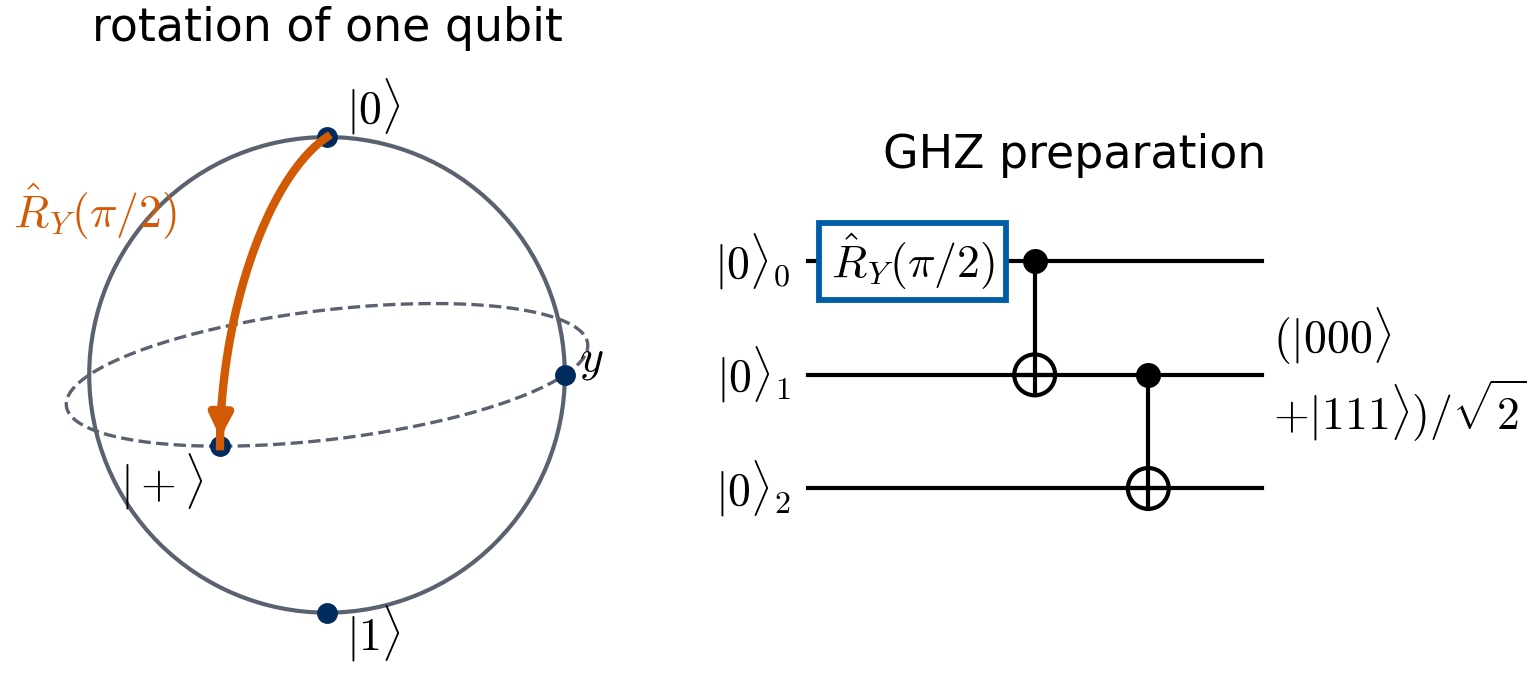

In [7]:
def bloch_vector(v):
    """Bloch vector (<X>, <Y>, <Z>) of a single-qubit state v (array of length 2)."""
    return np.real([np.conj(v) @ np.asarray(P) @ v for P in (X, Y, Z)])

def draw_bloch(ax):
    """Bloch sphere in an oblique projection, x axis towards the viewer, z up; returns the projection."""
    proj = lambda r: np.array([r[1] - 0.45 * r[0], r[2] - 0.30 * r[0]])
    ax.add_patch(Circle((0, 0), 1, fill=False, lw=1.0, color=UJGray))
    t = np.linspace(0, 2 * np.pi, 200)
    eq = np.array([proj((np.cos(s), np.sin(s), 0)) for s in t])
    ax.plot(eq[:, 0], eq[:, 1], color=UJGray, lw=0.8, ls="--")
    for r, lab, off in (((0, 0, 1), r"$|0\rangle$", (0.08, 0.06)), ((0, 0, -1), r"$|1\rangle$", (0.08, -0.16)),
                        ((1, 0, 0), r"$|+\rangle$", (-0.42, -0.22)), ((0, 1, 0), r"$y$", (0.06, 0.02))):
        p = proj(r); ax.plot(*p, "o", color=UJNavy, ms=4); ax.text(p[0] + off[0], p[1] + off[1], lab)
    ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal"); ax.axis("off")
    return proj

# Bloch-sphere path of R_Y(theta)|0>, theta from 0 to pi/2, computed with the gate
v0 = jnp.array([1, 0], dtype=CDTYPE)
path = np.array([bloch_vector(np.asarray(ry(t) @ v0)) for t in np.linspace(0, np.pi / 2, 40)])
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
proj = draw_bloch(axes[0])
pp = np.array([proj(r) for r in path])
axes[0].plot(pp[:, 0], pp[:, 1], color=DSOrange, lw=2)
axes[0].annotate("", xy=pp[-1], xytext=pp[-4], arrowprops=dict(arrowstyle="-|>", color=DSOrange, lw=2))
axes[0].text(-1.32, 0.62, r"$\hat R_Y(\pi/2)$", color=DSOrange)
axes[0].set_title("rotation of one qubit")

ax = axes[1]   # GHZ circuit on 3 qubits: R_Y(pi/2) on qubit 0, then CNOT 0->1 and CNOT 1->2
for q in range(3):
    ax.plot([0, 4], [-q, -q], color="k", lw=1, zorder=1); ax.text(-0.15, -q, rf"$|0\rangle_{q}$", ha="right", va="center")
ax.add_patch(Rectangle((0.1, -0.34), 1.65, 0.68, fc="white", ec=UJBlue, lw=1.4, zorder=2))
ax.text(0.925, 0, r"$\hat R_Y(\pi/2)$", ha="center", va="center", zorder=3)
for x, c, t in ((2.0, 0, 1), (3.0, 1, 2)):
    ax.plot([x, x], [-c, -t - 0.18], color="k", lw=1); ax.plot(x, -c, "o", color="k", ms=5)
    ax.add_patch(Circle((x, -t), 0.18, fill=False, color="k", lw=1)); ax.plot([x - 0.18, x + 0.18], [-t, -t], color="k", lw=1)
ax.text(4.1, -1, "$(|000\\rangle$\n$+|111\\rangle)/\\sqrt{2}$", va="center")
ax.set_xlim(-0.9, 5.6); ax.set_ylim(-2.6, 0.6); ax.set_aspect("equal"); ax.axis("off"); ax.set_title("GHZ preparation")
fig.tight_layout(); save(fig, "fig_lab055_recap"); plt.show()

The left panel shows the path of the Bloch vector of $\hat R_Y(\theta)|0\rangle$ for $\theta$ from $0$ to $\pi/2$, computed with the gate, from the north pole to $|+\rangle$ on the equator. The right panel is the GHZ circuit on three qubits, a rotation followed by two CNOTs. Rotations set the amplitudes, CNOTs spread them over several qubits, and every circuit of this notebook is built from these two kinds of gates.
<hr/>
## 2. Target states

All targets live on an open chain of $N$ qubits, with $N=2,4,6,8$. Even $N$ allow a cut into two halves of equal size for $S_{N/2}$. We collect six target families, two states written down directly and four ground states of spin chains.

### GHZ and W states

The GHZ state has $S_{N/2}=1$ for every $N$ and is prepared by one rotation and $N-1$ CNOTs. The W state
$$|W_N\rangle=\frac{1}{\sqrt N}\big(|10\dots0\rangle+|01\dots0\rangle+\dots+|0\dots01\rangle\big)$$
shares a single excitation among all qubits. For three qubits it cannot be converted into a GHZ state by local operations and classical communication, even with a success probability below one [W. Dür, G. Vidal, J. I. Cirac, Phys. Rev. A **62**, 062314 (2000), [doi:10.1103/PhysRevA.62.062314](https://doi.org/10.1103/PhysRevA.62.062314)]. Its amplitudes $1/\sqrt N$ require rotation angles that are not multiples of $\pi/2$. For $|W_4\rangle$ the half-chain cut gives the matrix $M$ with rows $a\in\{00,01,10,11\}$ of qubits 0, 1 and columns $b$ of qubits 2, 3. Only $M_{00,01}=M_{00,10}=M_{01,00}=M_{10,00}=1/2$ are non-zero, so $M$ has two singular values $1/\sqrt2$ and $S_{N/2}=1$ bit, the same as GHZ. The next cell prints the W state on four qubits and its entropy.

In [8]:
W4 = w_state(4)
print("W_4 =", show(W4))
print("Schmidt values across the half cut:", np.round(np.asarray(schmidt_values(W4, (0, 1))), 6)[:3],
      f"  S_N/2 = {float(entanglement_entropy(W4, (0, 1))):.6f} bit")

W_4 = +0.5000|0001>  +0.5000|0010>  +0.5000|0100>  +0.5000|1000>
Schmidt values across the half cut: [0.707107 0.707107 0.      ]   S_N/2 = 1.000000 bit


GHZ and W carry the same half-chain entropy, one bit, and still have very different structure. The compilation results below show how differently hard they are to prepare with a fixed gate layout.

### Transverse-field Ising chain

The transverse-field Ising (TFI) chain of $N$ spins $1/2$ with nearest-neighbour coupling $J>0$ in a transverse field $h$ has the Hamiltonian
$$\hat{\mathcal H}_{\rm TFI}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i ,$$
where $\hat Z_i$ and $\hat X_i$ are the Pauli matrices of spin $i$. The coupling favours parallel spins along $z$, the field favours every spin in $|+\rangle$ along $x$, and the two terms do not commute. For $h<J$ the coupling wins and the chain is a ferromagnet, with the order parameter $\langle \hat Z_i\rangle\neq0$ in the thermodynamic limit. In a finite chain the two ordered states $|0\dots0\rangle$ and $|1\dots1\rangle$ are coupled by the field, and the ground state is close to their symmetric superposition, a state of the GHZ type. For $h>J$ the field wins and the ground state approaches the product state $|+\dots+\rangle$, a paramagnet. At $h=J$ the chain has a continuous quantum phase transition. The model maps onto free fermions by the Jordan–Wigner transformation and is solved exactly [P. Pfeuty, Ann. Phys. **57**, 79 (1970), [doi:10.1016/0003-4916(70)90270-8](https://doi.org/10.1016/0003-4916(70)90270-8)]. At the critical point the entanglement entropy of a block grows logarithmically with its length [P. Calabrese, J. Cardy, J. Stat. Mech. (2004) P06002, [doi:10.1088/1742-5468/2004/06/P06002](https://doi.org/10.1088/1742-5468/2004/06/P06002)], and away from it the entropy saturates. We take $J=1$ and three fields, $h=0.5$ in the ferromagnet, $h=1$ at the critical point and $h=2$ in the paramagnet, the same choice as in the deep Q-learning notebook.

Two spins can be solved on paper. The states $|\Phi^\pm\rangle=(|00\rangle\pm|11\rangle)/\sqrt2$ and $|\Psi^\pm\rangle=(|01\rangle\pm|10\rangle)/\sqrt2$ have $\hat Z_0\hat Z_1=+1$ and $-1$, and $\hat X_0+\hat X_1$ maps $|\Phi^+\rangle$ to $2|\Psi^+\rangle$ and $|\Phi^-\rangle$ to zero. In the basis $\{|\Phi^+\rangle,|\Psi^+\rangle\}$ the Hamiltonian is the $2\times2$ matrix $\begin{pmatrix}-J&-2h\\-2h&J\end{pmatrix}$, so the ground-state energy is $E_0=-\sqrt{J^2+4h^2}$, which is $-\sqrt5$ at $h=J=1$. The Hamiltonian is stored as a list of local terms, and the Lanczos method of SmoQ.jax finds the ground state using only the product $\hat{\mathcal H}|\psi\rangle$ computed from the local terms. The next cell defines the Hamiltonian and compares the Lanczos energy for two spins with $-\sqrt5$.

In [9]:
J = 1.0
TFI_NAMES = {0.5: "TFI h=0.5", 1.0: "TFI h=1", 2.0: "TFI h=2"}      # the three fields h of the TFI targets
H_FIELDS = tuple(TFI_NAMES)

def tfi_terms(N, h, J=J):
    """H_TFI = -J sum Z_i Z_{i+1} - h sum X_i on an open chain, as a SmoQ.jax list of local terms."""
    return heisenberg_terms(N, Jxx=0.0, Jyy=0.0, Jzz=-J, hx=-h)

E0_lanczos, _ = lanczos_ground_state(tfi_terms(2, 1.0), 2)
print(f"N = 2, h = J = 1:  Lanczos E0 = {E0_lanczos:.12f},  -sqrt(5) = {-np.sqrt(5):.12f}")

N = 2, h = J = 1:  Lanczos E0 = -2.236067977500,  -sqrt(5) = -2.236067977500


The two numbers agree to all printed digits. Before choosing targets we look at the physics of the chain as a function of the field. For $N\le8$ the Hamiltonian is a $256\times256$ matrix at most, small enough for exact diagonalisation. The next cell diagonalises it on a grid of fields and plots two quantities of the ground state. The end-to-end correlation $C=\langle \hat Z_0\hat Z_{N-1}\rangle$ measures the ferromagnetic order of a finite chain, since $\langle \hat Z_i\rangle$ itself vanishes by the symmetry $\hat Z\to-\hat Z$ of $\hat{\mathcal H}_{\rm TFI}$. The half-chain entropy $S_{N/2}$ measures the entanglement between the two halves.

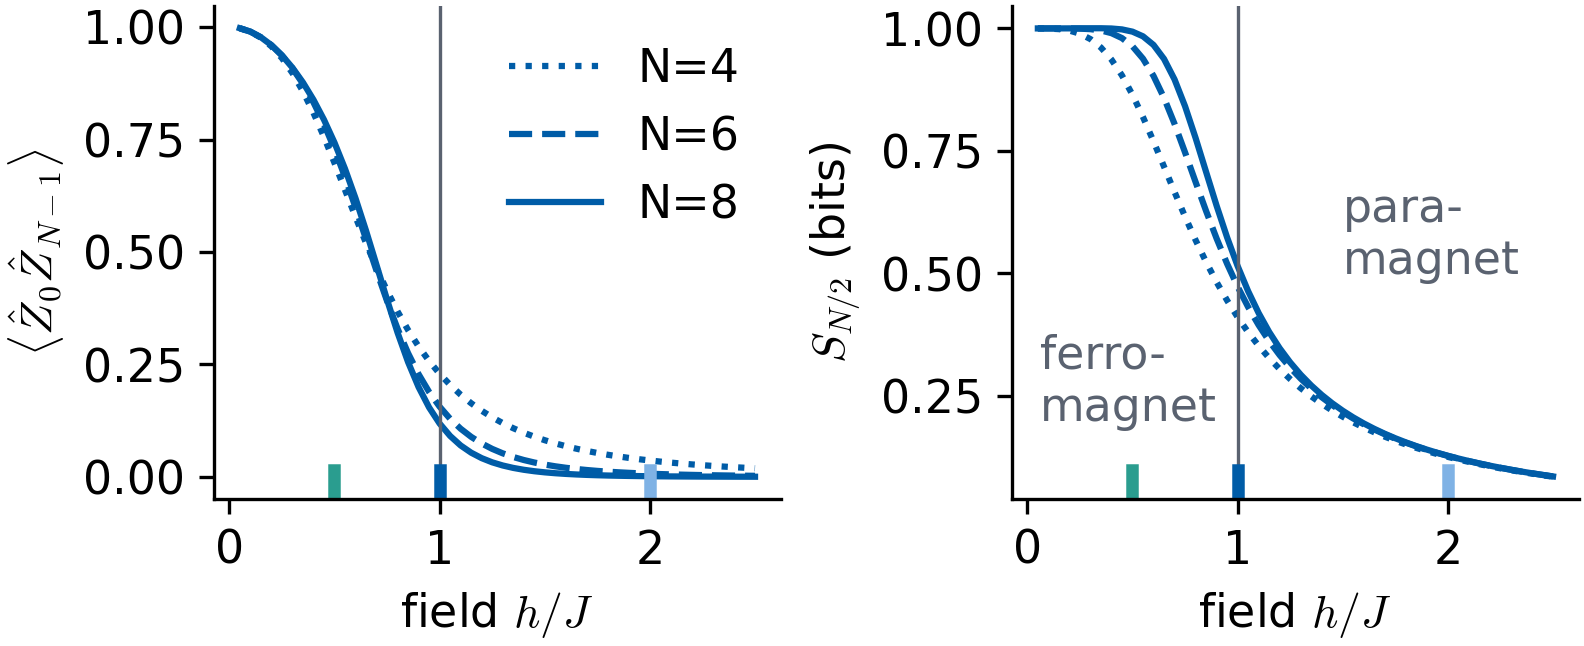

In [10]:
h_scan = np.linspace(0.05, 2.5, 50)
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.5), sharex=True)
for N, ls in zip((4, 6, 8), (":", "--", "-")):
    # H(h) = H_ZZ + h H_X is linear in h, so the two dense parts are built once per N
    H_zz = np.asarray(dense_hamiltonian(tfi_terms(N, 0.0), N))
    H_x = np.asarray(dense_hamiltonian(tfi_terms(N, 1.0), N)) - H_zz
    bits = (np.arange(2 ** N)[:, None] >> (N - 1 - np.arange(N))[None, :]) & 1
    ZZ_end = (1 - 2 * bits[:, 0]) * (1 - 2 * bits[:, -1])            # diagonal of Z_0 Z_{N-1}
    S_half = jax.jit(lambda p: entanglement_entropy(p, tuple(range(N // 2))))
    C_h, S_h = [], []
    for h in h_scan:
        w, v = np.linalg.eigh((H_zz + h * H_x).real)                  # H_TFI is a real symmetric matrix
        C_h.append(float(np.sum(ZZ_end * v[:, 0] ** 2)))
        S_h.append(float(S_half(jnp.asarray(v[:, 0], dtype=CDTYPE).reshape((2,) * N))))
    axes[0].plot(h_scan, C_h, ls=ls, color=UJBlue, label=f"N={N}")
    axes[1].plot(h_scan, S_h, ls=ls, color=UJBlue)
for ax in axes:
    ax.axvline(1.0, color=UJGray, lw=0.8); ax.set_xlabel(r"field $h/J$")
    for h in H_FIELDS:
        ax.axvline(h, ymax=0.06, color=FAMILY_STYLE[TFI_NAMES[h]]["color"], lw=3)
axes[0].set_ylabel(r"$\langle\hat Z_0\hat Z_{N-1}\rangle$"); axes[1].set_ylabel(r"$S_{N/2}$ (bits)")
axes[0].legend(loc="upper right")
axes[1].text(0.06, 0.2, "ferro-\nmagnet", color=UJGray); axes[1].text(1.5, 0.5, "para-\nmagnet", color=UJGray)
fig.tight_layout(); save(fig, "fig_lab055_tfi_phases"); plt.show()

The left panel shows the end-to-end correlation, close to one deep in the ferromagnet and falling to zero in the paramagnet. The drop sharpens with growing $N$ around $h=J$, the finite-size trace of the phase transition. The right panel shows the half-chain entropy, close to the one bit of the GHZ-type superposition for small $h$ and falling towards zero for large $h$. On chains this short the logarithmic growth at the critical point appears only as a small increase with $N$. The coloured ticks mark the three target fields $h=0.5$, $1$ and $2$, one in each regime.

### Non-integrable Ising chain

A longitudinal field destroys the free-fermion solution. We write the general Ising chain as
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i-g\sum_{i=0}^{N-1}\hat Z_i ,$$
with a longitudinal field $g$, so that $g=0$ is the TFI chain above. As non-integrable point we take the parameters of Kim and Huse [H. Kim, D. A. Huse, Phys. Rev. Lett. **111**, 127205 (2013), [doi:10.1103/PhysRevLett.111.127205](https://doi.org/10.1103/PhysRevLett.111.127205)], chosen there so that the chain is far from integrable. They write the coupling as $+\sum \hat Z_i\hat Z_{i+1}$ with unit strength, a transverse field $(5+\sqrt5)/8$ and a longitudinal field $(1+\sqrt5)/4$, all with a plus sign. In the convention above this is
$$J=-1,\qquad h=-\tfrac{5+\sqrt5}{8}\approx-0.905,\qquad g=-\tfrac{1+\sqrt5}{4}\approx-0.809 ,$$
an antiferromagnetic coupling. The signs of $h$ and $g$ could be flipped by the products $\prod_i\hat Z_i$ and $\prod_i\hat X_i$ of single-qubit gates, which do not change any entanglement, and we keep them as written. The sign of $J$ cannot be removed in this way while $g\neq0$. Kim and Huse also reduce the longitudinal field on the two end spins, and we keep it uniform, as the deep Q-learning notebook does, so that both notebooks compile the same states. Kim and Huse study the dynamics of this chain. We take only its Hamiltonian and compute its ground state with exact state vectors, since the ground state has no known closed form. We call it the non-integrable Ising ground state.

### All targets

The next cell builds every target. Each Lanczos ground state is checked against exact diagonalisation of the dense Hamiltonian, energy and state. All targets have real amplitudes up to a global phase. For GHZ and W this is visible from the definition. For both chains the off-diagonal matrix elements in the $\hat Z$ basis come only from the $\hat X$ terms, which are real, so the Hamiltonian is a real symmetric matrix and its non-degenerate ground state is real. The function `ground_state` fixes the global phase so that the largest amplitude is real and positive and checks that all amplitudes are then real. This property is used when the circuit template is chosen.

In [11]:
J_NI, H_NI, G_NI = -1.0, -(5 + np.sqrt(5)) / 8, -(1 + np.sqrt(5)) / 4    # Kim-Huse point in the convention of the text
FAMILIES = ["GHZ", "W"] + list(TFI_NAMES.values()) + ["non-integrable"]
NS = (2, 4, 6, 8)

def ising_terms(N, J, h, g):
    """H = -J sum Z_i Z_{i+1} - h sum X_i - g sum Z_i on an open chain, uniform fields."""
    return heisenberg_terms(N, Jxx=0.0, Jyy=0.0, Jzz=-J, hx=-h, hz=-g)

def ground_state(terms, N):
    """Lanczos ground state, checked against exact diagonalisation, with its largest amplitude real and positive."""
    E0, psi = lanczos_ground_state(terms, N)
    w, v = np.linalg.eigh(np.asarray(dense_hamiltonian(terms, N)))
    F_ed = float(fidelity_pure(psi, jnp.asarray(v[:, 0], dtype=CDTYPE).reshape((2,) * N)))
    assert abs(E0 - w[0]) < 1e-8 and F_ed > 1 - 1e-8, (E0, w[0], F_ed)
    big = psi.reshape(-1)[jnp.argmax(jnp.abs(psi.reshape(-1)))]
    psi = psi * jnp.conj(big) / jnp.abs(big)
    assert float(jnp.max(jnp.abs(psi.imag))) < 1e-8
    return psi

TARGETS = {}      # (family, N) -> dict(psi = target state, S = half-chain entropy in bits)
for N in NS:
    for fam in FAMILIES:
        if fam == "GHZ":
            psi = ghz_state(N)
        elif fam == "W":
            psi = w_state(N)
        elif fam.startswith("TFI"):
            psi = ground_state(tfi_terms(N, float(fam.split("=")[1])), N)
        else:
            psi = ground_state(ising_terms(N, J_NI, H_NI, G_NI), N)
        TARGETS[(fam, N)] = dict(psi=psi, S=float(entanglement_entropy(psi, tuple(range(N // 2)))))
print("all Lanczos ground states agree with exact diagonalisation and are real\n")
print("half-chain entropy S_N/2 in bits")
print(f"{'target':>15}" + "".join(f"{'N=' + str(N):>8}" for N in NS))
for fam in FAMILIES:
    print(f"{fam:>15}" + "".join(f"{TARGETS[(fam, N)]['S']:8.3f}" for N in NS))

all Lanczos ground states agree with exact diagonalisation and are real

half-chain entropy S_N/2 in bits
         target     N=2     N=4     N=6     N=8
            GHZ   1.000   1.000   1.000   1.000
              W   1.000   1.000   1.000   1.000
      TFI h=0.5   0.601   0.865   0.964   0.993
        TFI h=1   0.298   0.411   0.473   0.515
        TFI h=2   0.112   0.126   0.128   0.128
 non-integrable   0.220   0.399   0.394   0.474


The table is the entanglement map of the targets. GHZ and W carry one bit at every $N$. The TFI ground state in the ferromagnet approaches one bit as $N$ grows, the critical one grows slowly with $N$, the paramagnetic one stays small, and the non-integrable ground state lies well below one bit. These six families are the targets of every method below.
<hr/>
## 3. Circuit template

Compiling a target means choosing gates and their parameters. We fix the layout of the gates and leave only the angles free. The template has $D$ entangling layers,
$$|\psi(\boldsymbol\theta)\rangle=\hat R(\boldsymbol\theta_D)\,\hat U_{\rm ent}\,\hat R(\boldsymbol\theta_{D-1})\,\hat U_{\rm ent}\cdots \hat U_{\rm ent}\,\hat R(\boldsymbol\theta_0)\,|0\dots0\rangle ,$$
built from a rotation layer and an entangling layer,
$$\hat R(\boldsymbol\theta_t)=\prod_{q=0}^{N-1}\hat R_Y(\theta_{t,q}),\qquad \hat U_{\rm ent}=\widehat{\mathrm{CNOT}}_{N-2\to N-1}\cdots\widehat{\mathrm{CNOT}}_{1\to2}\,\widehat{\mathrm{CNOT}}_{0\to1}.$$
Here $\theta_{t,q}$ is the angle on qubit $q$ in rotation layer $t=0,\dots,D$, and $\boldsymbol\theta$ is the array of all $n_{\rm ang}=N(D+1)$ angles. The template holds $D(N-1)$ CNOT gates. $\hat R_Y$ and CNOT are real matrices, so the template produces real states only. All targets are real, and leaving out $\hat R_Z$ halves the number of angles without losing any target.

The two-qubit template with $D=1$ contains the Bell circuit. With $\theta_{0,0}=\pi/2$ and all other angles zero it is $\hat R_Y(\pi/2)$ on qubit 0 followed by one CNOT. The next cell defines the template, with one function per layer, and evaluates it on these angles.

In [12]:
def ry_layer(psi, angles):
    """Rotation layer R(theta_t): R_Y(angles[q]) on every qubit q, one einsum per qubit."""
    for q in range(psi.ndim):
        psi = apply_gate(psi, ry(angles[q]), [q])
    return psi

def cnot_ladder(psi):
    """Entangling layer U_ent: CNOT(0->1), CNOT(1->2), ..., CNOT(N-2 -> N-1)."""
    for q in range(psi.ndim - 1):
        psi = apply_gate(psi, CNOT, [q, q + 1])
    return psi

def template_state(theta):
    """|psi(theta)> = R(theta_D) U_ent ... U_ent R(theta_0) |0...0> for theta of shape (D+1, N), a lax.scan over layers."""
    def layer(psi, angles):
        return cnot_ladder(ry_layer(psi, angles)), None
    psi, _ = jax.lax.scan(layer, zero_state(theta.shape[1]), theta[:-1])
    return ry_layer(psi, theta[-1])

def template_fidelity(theta, target):
    """F(theta) = |<target|psi(theta)>|^2."""
    return fidelity_pure(target, template_state(theta))

theta_bell = jnp.array([[jnp.pi / 2, 0.0], [0.0, 0.0]])      # rows t = 0, 1; columns q = 0, 1
print("template, N = 2, D = 1:", show(template_state(theta_bell)))
print("F with the Bell state  :", float(template_fidelity(theta_bell, bell_state("phi+"))))

template, N = 2, D = 1: +0.7071|00>  +0.7071|11>
F with the Bell state  : 0.9999999999999998


The template reproduces the Bell state with $F=1$. With $D=1$, $\theta_{0,0}=\pi/2$ and all other angles zero, the $N$-qubit template is the GHZ circuit of the first section for every $N$. The next cell checks this for $N=4$ and $8$, and checks on a random six-qubit template that the output is real and normalised, then draws the template.

In [13]:
for N in (4, 8):
    theta = jnp.zeros((2, N)).at[0, 0].set(jnp.pi / 2)
    assert abs(float(template_fidelity(theta, ghz_state(N))) - 1) < TOL
psi_r = template_state(jax.random.uniform(key, (4, 6), maxval=2 * jnp.pi))
assert abs(float(jnp.linalg.norm(psi_r)) - 1) < TOL and float(jnp.max(jnp.abs(psi_r.imag))) < TOL
print("GHZ from the template for N = 4, 8; random template output real and normalised")

GHZ from the template for N = 4, 8; random template output real and normalised


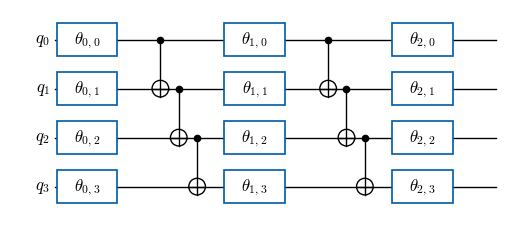

In [14]:
def draw_circuit(ax, N, D, angles=None, types=None, title=None):
    """Circuit diagram: R_Y boxes with angles (D+1, N), symbols when None; two-qubit gates types (D, N-1)
    with 1 = CNOT (dot and circled plus), 2 = CZ (two dots), 0 = none; CNOT on every bond when None."""
    x, dx_rot, dx_cx = 0.75, 1.5, 0.75
    xs_rot = []
    for t in range(D + 1):
        xs_rot.append(x); x += dx_rot
        if t < D:
            for q in range(N - 1):
                xc = x + 0.5 * dx_cx * q
                e = 1 if types is None else int(types[t][q])
                if e == 1:
                    ax.plot([xc, xc], [-q, -q - 1 - 0.17], color="k", lw=0.9); ax.plot(xc, -q, "o", color="k", ms=4)
                    ax.add_patch(Circle((xc, -q - 1), 0.17, fill=False, color="k", lw=0.9))
                    ax.plot([xc - 0.17, xc + 0.17], [-q - 1, -q - 1], color="k", lw=0.9)
                elif e == 2:
                    ax.plot([xc, xc], [-q, -q - 1], color=DSOrange, lw=0.9)
                    ax.plot([xc, xc], [-q, -q - 1], "o", color=DSOrange, ms=4)
            x += 0.5 * dx_cx * (N - 1) + 0.8
    for q in range(N):
        ax.plot([0.1, x], [-q, -q], color="k", lw=0.9, zorder=0)
        ax.text(0.0, -q, rf"$q_{q}$", ha="right", va="center")
    for t, xr in enumerate(xs_rot):
        for q in range(N):
            ax.add_patch(Rectangle((xr - 0.62, -q - 0.34), 1.24, 0.68, fc="white", ec=UJBlue, lw=1.1, zorder=2))
            if angles is None:
                lab = rf"$\theta_{{{t},{q}}}$"
            else:
                a = (float(angles[t, q]) + np.pi) % (2 * np.pi) - np.pi      # angle wrapped into (-pi, pi]
                lab = f"{a:.2f}"
            ax.text(xr, -q, lab, ha="center", va="center", fontsize=11, zorder=3)
    ax.set_xlim(-0.8, x + 0.1); ax.set_ylim(-N + 0.4, 0.6); ax.axis("off"); ax.set_aspect("equal")
    if title: ax.set_title(title)
fig, ax = plt.subplots(figsize=(5.5, 2.2))
draw_circuit(ax, 4, 2)
fig.tight_layout(); save(fig, "fig_lab055_template"); plt.show()

The diagram shows the template for $N=4$ qubits and $D=2$ entangling layers. Every box is a rotation $\hat R_Y(\theta_{t,q})$, each entangling layer is the CNOT ladder from qubit $q_0$ down to $q_3$, and time runs from left to right. Compiling a target with this template means finding the twelve angles, and the number of layers $D$ sets the number of CNOT gates.
<hr/>
## 4. Successful tested template depths

Before training an agent, we search for a sufficient template depth for each target using the full circuit model. Numerical success establishes a sufficient depth. Failed starts at smaller depths supply no lower bound. The template output is a differentiable function of the angles, so `jax.grad` gives the exact gradient of $F(\boldsymbol\theta)$ through the simulator, and gradient ascent climbs it. This is the reference method of the notebook. It requires the model, the function $\boldsymbol\theta\mapsto|\psi(\boldsymbol\theta)\rangle$ written as code.

The same gradient can be measured on a quantum device without any simulator. For one qubit and the target $|1\rangle$, $F(\theta)=|\langle1|\hat R_Y(\theta)|0\rangle|^2=\sin^2\frac{\theta}{2}=\frac12(1-\cos\theta)$, so $F'(\theta)=\frac12\sin\theta$. The difference of two fidelities shifted by $\pm\pi/2$ gives
$$\frac{F(\theta+\frac{\pi}{2})-F(\theta-\frac{\pi}{2})}{2}=\frac{\cos(\theta-\frac{\pi}{2})-\cos(\theta+\frac{\pi}{2})}{4}=\frac12\sin\theta ,$$
which is the derivative itself, free of any finite-difference error. For every gate $e^{-i\theta\hat{\mathcal G}/2}$ whose generator satisfies $\hat{\mathcal G}^2=\mathbb 1$ the fidelity is a sinusoid in each angle, and the parameter-shift rule
$$\frac{\partial F}{\partial\theta_k}=\frac{F(\boldsymbol\theta+\tfrac{\pi}{2}\mathbf e_k)-F(\boldsymbol\theta-\tfrac{\pi}{2}\mathbf e_k)}{2}$$
holds exactly, with $\mathbf e_k$ the unit vector of angle $k$ [K. Mitarai, M. Negoro, M. Kitagawa, K. Fujii, Phys. Rev. A **98**, 032309 (2018), [doi:10.1103/PhysRevA.98.032309](https://doi.org/10.1103/PhysRevA.98.032309); M. Schuld, V. Bergholm, C. Gogolin, J. Izaac, N. Killoran, Phys. Rev. A **99**, 032331 (2019), [doi:10.1103/PhysRevA.99.032331](https://doi.org/10.1103/PhysRevA.99.032331)]. One gradient then costs $2n_{\rm ang}$ fidelity evaluations for $n_{\rm ang}$ angles. The next cell checks the one-qubit formula and then the rule on a four-qubit template against `jax.grad`.

In [15]:
F1 = lambda th: fidelity_pure(jnp.array([0, 1], dtype=CDTYPE), ry(th) @ ket0)     # F(theta) = sin^2(theta/2)
th0 = 0.8
print(f"one qubit: shift rule {float((F1(th0 + np.pi / 2) - F1(th0 - np.pi / 2)) / 2):.10f}, "
      f"jax.grad {float(jax.grad(F1)(th0)):.10f}, sin(theta)/2 {np.sin(th0) / 2:.10f}")

theta_t = jax.random.uniform(key, (3, 4), maxval=2 * jnp.pi)
target_t = TARGETS[("TFI h=1", 4)]["psi"]
g_auto = jax.grad(template_fidelity)(theta_t, target_t)
g_shift = parameter_shift_grad(lambda th: template_fidelity(th, target_t), theta_t)
print(f"N = 4, D = 2: largest difference between parameter shift and jax.grad {float(jnp.max(jnp.abs(g_auto - g_shift))):.1e}")

one qubit: shift rule 0.3586780454, jax.grad 0.3586780454, sin(theta)/2 0.3586780454


N = 4, D = 2: largest difference between parameter shift and jax.grad 5.6e-17


The three numbers for one qubit agree, and on four qubits the two gradients agree to machine precision. Gradient ascent is therefore a method that a device could also run, at the price of $2n_{\rm ang}$ fidelity measurements per step.

The next cell defines gradient ascent with the Adam optimiser on $1-F(\boldsymbol\theta)$, from a random start with small angles, as one compiled `lax.scan` over the steps. A run on the W state with $N=4$ and $D=2$ shows the fidelity along the ascent.

In [16]:
GA_STEPS, GA_LR, GA_STARTS, F_GOAL = 400, 0.05, 4, 0.99

@partial(jax.jit, static_argnames=("D", "N", "steps"))
def gradient_ascent(key, target, D, N, steps=GA_STEPS, lr=GA_LR):
    """Adam on 1 - F(theta) through the simulator; returns the final angles and F at every step."""
    theta = 0.1 * jax.random.normal(key, (D + 1, N))
    opt = optax.adam(lr)
    loss_and_grad = jax.value_and_grad(lambda th: 1.0 - template_fidelity(th, target))
    def step(carry, _):
        theta, state = carry
        loss, g = loss_and_grad(theta)
        upd, state = opt.update(g, state)
        return (optax.apply_updates(theta, upd), state), 1.0 - loss
    (theta, _), F_steps = jax.lax.scan(step, (theta, opt.init(theta)), None, length=steps)
    return theta, F_steps

theta_W, F_steps = gradient_ascent(jax.random.PRNGKey(1), TARGETS[("W", 4)]["psi"], 2, 4)
print("W, N = 4, D = 2: F after steps 1, 50, 100, 200, 400 =", np.round(np.asarray(F_steps)[[0, 49, 99, 199, 399]], 5))

W, N = 4, D = 2: F after steps 1, 50, 100, 200, 400 = [0.00652 0.91931 0.99976 1.      1.     ]


The fidelity rises from the value of the nearly empty circuit to one within a few hundred steps. A single start can end in a local maximum, so every target is run from four starts, and the best one counts. The depth $D^\ast$ of a target is the smallest $D$ at which the best start reaches $F\ge0.99$. The next cell scans $D=1,2,\dots$ for every target until this happens or $D=N$.

In [17]:
@partial(jax.jit, static_argnames=("D", "N"))
def ga_starts(target, D, N, seed=1):
    """Gradient ascent from GA_STARTS random starts at once (vmap), the same starts for every target."""
    keys = jax.random.split(jax.random.PRNGKey(seed), GA_STARTS)
    return jax.vmap(lambda k: gradient_ascent(k, target, D, N))(keys)

t0 = time.time()
GA = {}            # (family, N) -> dict(D_star, F_by_D = best F for each D, F_steps of the starts at D_star)
for N in NS:
    for fam in FAMILIES:
        F_by_D = {}
        for D in range(1, N + 1):
            theta, F_steps = ga_starts(TARGETS[(fam, N)]["psi"], D, N)
            F_by_D[D] = float(np.asarray(F_steps)[:, -1].max())
            if F_by_D[D] >= F_GOAL:
                break
        GA[(fam, N)] = dict(D_star=D, F_by_D=F_by_D, F_steps=np.asarray(F_steps), reached=F_by_D[D] >= F_GOAL)
    print(f"N={N}: " + ", ".join(f"{fam} D*={GA[(fam, N)]['D_star']}" for fam in FAMILIES), f"[{time.time() - t0:.0f} s]")
T_GA = time.time() - t0

N=2: GHZ D*=1, W D*=1, TFI h=0.5 D*=1, TFI h=1 D*=1, TFI h=2 D*=1, non-integrable D*=1 [1 s]


N=4: GHZ D*=1, W D*=2, TFI h=0.5 D*=2, TFI h=1 D*=1, TFI h=2 D*=1, non-integrable D*=1 [4 s]


N=6: GHZ D*=1, W D*=4, TFI h=0.5 D*=2, TFI h=1 D*=2, TFI h=2 D*=1, non-integrable D*=2 [15 s]


N=8: GHZ D*=1, W D*=8, TFI h=0.5 D*=2, TFI h=1 D*=2, TFI h=2 D*=1, non-integrable D*=3 [48 s]


The next figure shows the result of the scan for $N=4,6,8$. For the W state on eight qubits the scan stopped at its upper limit $D=N=8$, and the printed output does not state whether $F\ge0.99$ was reached there. The value $D^\ast=8$ for $W_8$ is therefore not confirmed as a successful depth, and the figure gives the best infidelity reached at each scanned depth.

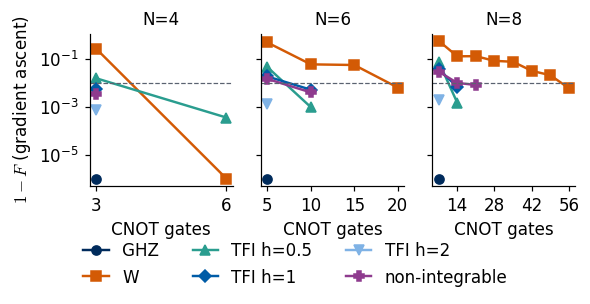

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(5.5, 2.4), sharey=True)
for ax, N in zip(axes, NS[1:]):
    for fam in FAMILIES:
        d = GA[(fam, N)]["F_by_D"]
        Ds = np.array(sorted(d)); F = np.array([d[l] for l in Ds])
        st = FAMILY_STYLE[fam]
        ax.semilogy(Ds * (N - 1), np.clip(1 - F, 1e-6, None), color=st["color"], marker=st["marker"], ms=6, lw=1.6)
    ax.axhline(1 - F_GOAL, color=UJGray, lw=0.8, ls="--")
    ax.set_title(f"N={N}"); ax.set_xlabel("CNOT gates")
    Dmax = max(max(GA[(f, N)]["F_by_D"]) for f in FAMILIES)
    ticks = np.arange(1, Dmax + 1) * (N - 1)
    ax.set_xticks(ticks if len(ticks) <= 4 else ticks[1::2])
axes[0].set_ylabel(r"$1-F$ (gradient ascent)")
handles = [Line2D([], [], ls="-", lw=1.6, ms=6, **FAMILY_STYLE[f]) for f in FAMILIES]
fig.legend(handles, FAMILIES, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.17), handlelength=1.5)
fig.tight_layout(); save(fig, "fig_lab055_depth"); plt.show()

Each panel shows the infidelity $1-F$ of the best gradient-ascent start against the number of CNOT gates $D(N-1)$, for $D=1,2,\dots$ until $F\ge0.99$ (dashed line) or $D=N$. GHZ is reached with one entangling layer for every $N$. The W state, with the same half-chain entropy of one bit, has the deepest successful tested template in this search. The GHZ amplitudes fit the CNOT ladder directly. Known circuits for the W state use rotations controlled by other qubits, while this numerical search finds sufficient templates with several layers. The ground states lie in between. Entanglement entropy alone does not set the depth, and the structure of the state relative to the gate set matters as well. The values $D^\ast$ found here fix the template depth for the agent, so that the agent is asked to find angles that are known to exist.
<hr/>
## 5. Compilation as a decision process

Reinforcement learning describes a task as a sequence of decisions. An agent observes a state $s_t$, takes an action, and the environment returns the next state and a reward $r_{t+1}$. The rewards of one episode add up to the return $G=\sum_tr_{t+1}$, and the agent learns a policy, a rule for choosing actions, that makes the expected return large.

### Episode, actions and reward

An episode builds one circuit in $D+1$ steps $t=0,\dots,D$, layer by layer along the template. At every step the agent takes two kinds of decisions. It chooses the $N$ rotation angles $\mathbf a_t=(a_{t,0},\dots,a_{t,N-1})$, real numbers, and for every bond $(q,q+1)$ of the entangling layer it chooses a gate type $e_{t,q}\in\{\text{none},\mathrm{CNOT},\mathrm{CZ}\}$, a discrete choice. The environment applies $\hat R(\mathbf a_t)$, then the chosen two-qubit gates from bond $(0,1)$ to bond $(N-2,N-1)$, and at the last step $t=D$ only the rotations. With every $e_{t,q}=\mathrm{CNOT}$ the circuit is the template of the previous sections, so the agent can reproduce it, replace CNOT gates by CZ gates or leave bonds empty. The number of layers $D$ is the depth $D^\ast$ found by gradient ascent, so that a circuit with $F\ge0.99$ is known to exist.

After the last layer the reward is the fidelity $F=|\langle\psi_{\rm target}|\psi\rangle|^2$, all earlier rewards are zero, and the return is $G=F$. A per-step reward $r_{t+1}=F_t-F_{t-1}$, with $F_t$ the fidelity after layer $t$, would sum to $F_D-F_{-1}$, the same objective up to the constant fidelity $F_{-1}$ of $|0\dots0\rangle$. The intermediate states of a layered circuit have no reason to resemble the target, and the information supplied by a per-step reward would need a separate comparison. We use final fidelity.

The agent observes the state features $s_t$, the $2^N$ real amplitudes of the current state (all states of this circuit are real) together with the one-hot index of the step $t$, a vector of $D+1$ entries that are zero except for a one at position $t$. In the simulation the amplitudes are available. On a device they are not, and a separately trained history-based policy could use the list of applied gates. That history specifies the intended circuit. Estimating the actual device state requires a model or measurements. The reward is in both cases only the fidelity.

The next cell writes the environment as small functions. `env_reset` starts an episode, `entangling_layer` applies the chosen two-qubit gates, `env_step` applies one step and returns the reward, and `observe` returns the state features. `circuit_fidelity` plays a whole circuit of given angles and gate types and returns its fidelity.

In [19]:
NONE, CX, CZ_ = 0, 1, 2                          # gate types e of a bond
GATE_TYPES = ("none", "CNOT", "CZ")

class EnvState(NamedTuple):
    psi: jax.Array        # quantum state, tensor of shape (2,)*N
    t: jax.Array          # index t of the next layer, 0..D

def env_reset(N):
    """Start of an episode: |0...0>, t = 0."""
    return EnvState(zero_state(N), jnp.array(0))

def entangling_layer(psi, e):
    """Gate e[q] in {none, CNOT, CZ} on the bond (q, q+1), for q = 0..N-2 in this order."""
    for q in range(psi.ndim - 1):
        psi_cx, psi_cz = apply_gate(psi, CNOT, [q, q + 1]), apply_gate(psi, CZ, [q, q + 1])
        psi = jnp.where(e[q] == CX, psi_cx, jnp.where(e[q] == CZ_, psi_cz, psi))
    return psi

def env_step(s, a_t, e_t, target, D):
    """Apply R(a_t), then the entangling layer e_t unless t = D. Reward r_{t+1} = F after the last layer, 0 before."""
    last = s.t == D
    psi = ry_layer(s.psi, a_t)
    psi = jnp.where(last, psi, entangling_layer(psi, e_t))
    r_next = jnp.where(last, fidelity_pure(target, psi), 0.0)
    return EnvState(psi, s.t + 1), r_next

def observe(s, D):
    """State features s_t: the real amplitudes of the state and the one-hot step index t."""
    return jnp.concatenate([s.psi.reshape(-1).real, jax.nn.one_hot(s.t, D + 1)])

def circuit_fidelity(angles, types, target):
    """F of the circuit with angles (D+1, N) and gate types (D+1, N-1), played through the environment."""
    D = angles.shape[0] - 1
    s = env_reset(angles.shape[1])
    for t in range(D + 1):
        s, r_next = env_step(s, angles[t], types[t], target, D)
    return r_next

# check: with CNOT on every bond the environment plays the template
theta_r = jax.random.uniform(key, (3, 4), maxval=2 * jnp.pi)
F_env = circuit_fidelity(theta_r, jnp.full((3, 3), CX), TARGETS[("W", 4)]["psi"])
assert abs(float(F_env - template_fidelity(theta_r, TARGETS[("W", 4)]["psi"]))) < TOL
print("environment with CNOT on every bond = template")

environment with CNOT on every bond = template


The environment reproduces the template when every bond carries a CNOT. One episode with chosen actions makes the bookkeeping concrete. For $N=2$, $D=1$ and the Bell target we play $\mathbf a_0=(\pi/2,0)$ with a CNOT on the single bond, then $\mathbf a_1=(0,0)$, the Bell circuit of the template section. The observation has $2^N=4$ amplitudes and $D+1=2$ entries of the step index.

In [20]:
s = env_reset(2)
for a_t, e_t in ((jnp.array([jnp.pi / 2, 0.0]), jnp.array([CX])), (jnp.array([0.0, 0.0]), jnp.array([NONE]))):
    print(f"t = {int(s.t)}  observation = {np.round(np.asarray(observe(s, 1)), 4)}")
    s, r_next = env_step(s, a_t, e_t, bell_state("phi+"), 1)
    print(f"       a_t = {np.round(np.asarray(a_t), 4)}, e_t = {GATE_TYPES[int(e_t[0])]}  ->  {show(s.psi)},  r_(t+1) = {float(r_next):.4f}")

t = 0  observation = [1. 0. 0. 0. 1. 0.]


       a_t = [1.5708 0.    ], e_t = CNOT  ->  +0.7071|00>  +0.7071|11>,  r_(t+1) = 0.0000
t = 1  observation = [0.7071 0.     0.     0.7071 0.     1.    ]
       a_t = [0. 0.], e_t = none  ->  +0.7071|00>  +0.7071|11>,  r_(t+1) = 1.0000


The first observation is the state $|00\rangle$, amplitudes $(1,0,0,0)$, and the step index $t=0$. The second observation is already the Bell state, amplitudes $(0.7071,0,0,0.7071)$. The reward is zero after the first step and one after the second, when the episode ends in the Bell state. The entangling choice at the last step is ignored, since the last layer has rotations only.

### Continuous actions

A deep Q-network (DQN) learns the value $Q(s,a)$ of every action $a$ in every state, acts by $\arg\max_aQ(s,a)$, and its training target contains $\max_{a'}Q(s',a')$ [V. Mnih et al., Nature **518**, 529 (2015), [doi:10.1038/nature14236](https://doi.org/10.1038/nature14236)]. With a list of discrete actions both maxima are a search over the list. With continuous angles $\mathbf a_t\in\mathbb R^N$ both become optimisation problems over a continuum, to be solved at every step of every episode. Discretising each angle into $K$ values turns the rotations of one step into $K^N$ discrete actions, which the next cell counts.

In [21]:
for K in (4, 8, 16):
    print(f"K = {K:2d} values per angle: " + ", ".join(f"N={N}: {K**N:,} actions" for N in NS))

K =  4 values per angle: N=2: 16 actions, N=4: 256 actions, N=6: 4,096 actions, N=8: 65,536 actions
K =  8 values per angle: N=2: 64 actions, N=4: 4,096 actions, N=6: 262,144 actions, N=8: 16,777,216 actions
K = 16 values per angle: N=2: 256 actions, N=4: 65,536 actions, N=6: 16,777,216 actions, N=8: 4,294,967,296 actions


Eight values per angle on eight qubits already give almost 17 million actions per step, one output of the Q-network each. We therefore learn the policy itself, a probability distribution over actions. For the angles it is a Gaussian with a mean and a width, and for the gate type of every bond it is a softmax over the three types. Policy gradient treats both kinds of action in the same way.
<hr/>
## 6. Policy gradient

### The policy-gradient identity

A stochastic policy $\pi_\phi(\mathbf a\,|\,s)$ is a probability density over actions with parameters $\phi$. It gives every trajectory $\tau=(s_0,\mathbf a_0,\dots,s_D,\mathbf a_D)$ the probability $p_\phi(\tau)=\prod_t\pi_\phi(\mathbf a_t|s_t)$, times the transition probabilities of the environment, which do not depend on $\phi$ (here the transitions are deterministic). The expected return is $\mathcal J(\phi)=\langle G\rangle=\int d\tau\,p_\phi(\tau)\,G(\tau)$, and with $\nabla_\phi p=p\,\nabla_\phi\ln p$
$$\begin{aligned}\nabla_\phi\mathcal J(\phi)&=\int d\tau\,p_\phi(\tau)\,G(\tau)\,\nabla_\phi\ln p_\phi(\tau)\\&=\Big\langle G\sum_{t=0}^{D}\nabla_\phi\ln\pi_\phi(\mathbf a_t|s_t)\Big\rangle .\end{aligned}$$
The right-hand side is an average over episodes played with the current policy. It needs the returns and the policy, and neither the derivative of the reward with respect to the actions nor a model of the environment. Estimating it from sampled episodes is the REINFORCE algorithm [Williams (1992), cited above; R. S. Sutton, A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed. (MIT Press, 2018), <http://incompleteideas.net/book/the-book-2nd.html>]. Since $\langle\nabla_\phi\ln\pi_\phi\rangle=\nabla_\phi\int\pi_\phi=\nabla_\phi1=0$, any constant baseline $b$ can be subtracted from $G$ without changing the average, and a good baseline reduces the statistical error. We estimate the gradient from a batch of $B$ episodes and use the batch mean $\bar G$ as baseline.

### Gaussian policy

For a continuous angle the policy is a Gaussian with mean $\mu$ and width $\sigma=e^\nu$, where the log-width $\nu$ is the parameter that is trained, so that $\sigma$ stays positive. For one angle
$$\ln\pi(a)=-\frac{(a-\mu)^2}{2\sigma^2}-\nu-\tfrac12\ln2\pi ,\qquad \frac{\partial\ln\pi}{\partial\mu}=\frac{a-\mu}{\sigma^2},\qquad \frac{\partial\ln\pi}{\partial\nu}=\frac{(a-\mu)^2}{\sigma^2}-1 .$$
The mean moves towards sampled angles whose return lies above the baseline. The width shrinks when the better samples lie closer to the mean than one standard deviation, and grows when they lie farther out. As the policy finds a good angle, its width contracts, and $\sigma$ measures how sure the policy is. For several angles the log-likelihoods add. The next cell writes $\ln\pi$ and checks it against the Gaussian density of `jax.scipy`.

In [22]:
def gaussian_log_prob(a, mu, nu):
    """ln pi(a) of independent Gaussians with means mu and widths sigma = exp(nu), summed over components."""
    return jnp.sum(-0.5 * ((a - mu) / jnp.exp(nu)) ** 2 - nu - 0.5 * jnp.log(2 * jnp.pi))

a_chk, mu_chk, sigma_chk = jnp.array([0.3, -1.0]), jnp.array([0.1, 0.5]), jnp.array([0.7, 1.3])
print(float(gaussian_log_prob(a_chk, mu_chk, jnp.log(sigma_chk))),
      float(jnp.sum(jax.scipy.stats.norm.logpdf(a_chk, mu_chk, sigma_chk))))

-2.4500631868414975 -2.450063186841497


### Policy gradient on one qubit

The identity can be checked on one qubit, where every average is known in closed form. The action is one angle $a\sim\mathcal N(\mu,\sigma^2)$, the circuit is $\hat R_Y(a)|0\rangle$, and the target is $|1\rangle$, so $G=F=\sin^2\frac a2=\frac12(1-\cos a)$. The Gaussian average of $\cos a$ is $e^{-\sigma^2/2}\cos\mu$, hence
$$\mathcal J=\langle G\rangle=\tfrac12\big(1-e^{-\sigma^2/2}\cos\mu\big),\qquad \partial_\mu\mathcal J=\tfrac12e^{-\sigma^2/2}\sin\mu .$$
The next cell draws $2\times10^5$ angles at $\mu=1$, $\sigma=0.5$, computes their rewards with the gate, and averages $(G-b)\,(a-\mu)/\sigma^2$ without and with the baseline $b=\bar G$.

In [23]:
ket1 = jnp.array([0, 1], dtype=CDTYPE)
reward_1q = lambda a: fidelity_pure(ket1, ry(a) @ ket0)            # G = F = sin^2(a/2)

mu, sigma, n_mc = 1.0, 0.5, 200_000
a = mu + sigma * jax.random.normal(jax.random.PRNGKey(3), (n_mc,))   # a = mu + sigma u, u standard normal
G = jax.vmap(reward_1q)(a)
score_mu = (a - mu) / sigma**2                                     # d ln pi / d mu
for name, b in (("without baseline", 0.0), ("with baseline", float(G.mean()))):
    est = (G - b) * score_mu
    print(f"REINFORCE {name:17s}: {float(est.mean()):.4f} +- {float(est.std() / np.sqrt(n_mc)):.4f}"
          f"   (spread of one sample {float(est.std()):.3f})")
print(f"exact d<G>/d mu              : {0.5 * np.exp(-sigma**2 / 2) * np.sin(mu):.4f}")

REINFORCE without baseline : 0.3712 +- 0.0018   (spread of one sample 0.803)
REINFORCE with baseline    : 0.3711 +- 0.0011   (spread of one sample 0.498)
exact d<G>/d mu              : 0.3713


Both estimates agree with the exact derivative within their statistical errors, and the baseline reduces the spread of a single-episode estimate. The estimate used only sampled rewards. It never differentiated the circuit.

Training on this one-qubit problem shows the whole method with two parameters, $\mu$ and the log-width $\nu=\ln\sigma$. Here $\nu$ is a free parameter without any bound, so that the width can shrink as far as the training drives it. Each update draws $B=32$ angles, computes the advantages $A_i=(G_i-\bar G)/\mathrm{std}(G)$, and moves both parameters along the batch averages of $A_i\,\partial\ln\pi/\partial\mu$ and $A_i\,\partial\ln\pi/\partial\nu$, written out with the formulas above. Dividing by the standard deviation of the batch rescales the step of each update, which keeps it useful when all rewards of a batch are close to one. The best policy has $\mu=\pi$, where $F=1$, and $\sigma\to0$.

update   0: mu = 0.3000  sigma = 0.5000  batch mean of F = 0.0688
update  50: mu = 2.1935  sigma = 1.4402  batch mean of F = 0.5761
update 100: mu = 3.1553  sigma = 0.0697  batch mean of F = 0.9987
update 200: mu = 3.1462  sigma = 0.0015  batch mean of F = 1.0000
update 399: mu = 3.1494  sigma = 0.0001  batch mean of F = 1.0000


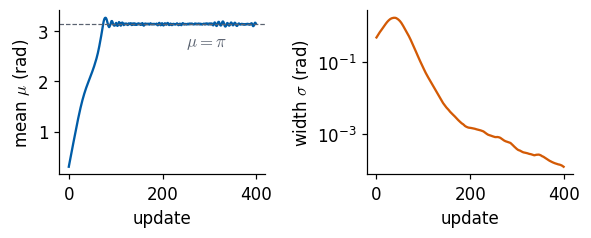

In [24]:
@jax.jit
def reinforce_one_qubit(key, mu=0.3, sigma=0.5, iters=400, B=32, lr=0.05):
    """REINFORCE for a ~ N(mu, sigma^2), reward sin^2(a/2); the score-function gradients written out."""
    phi = jnp.array([mu, jnp.log(sigma)])                          # parameters (mu, nu), nu = ln sigma unbounded
    opt = optax.adam(lr)
    def update(carry, k):
        phi, state = carry
        mu, sigma = phi[0], jnp.exp(phi[1])
        a = mu + sigma * jax.random.normal(k, (B,))
        G = jax.vmap(reward_1q)(a)
        A = (G - G.mean()) / (G.std() + 1e-8)
        grad = jnp.array([jnp.mean(A * (a - mu) / sigma**2),                   # d<G>/d mu
                          jnp.mean(A * ((a - mu) ** 2 / sigma**2 - 1))])       # d<G>/d nu
        upd, state = opt.update(-grad, state)                                  # ascent
        return (optax.apply_updates(phi, upd), state), (mu, sigma, G.mean())
    _, (mus, sigmas, G_mean) = jax.lax.scan(update, (phi, opt.init(phi)), jax.random.split(key, iters))
    return mus, sigmas, G_mean

mus, sigmas, G_mean = (np.asarray(x) for x in reinforce_one_qubit(jax.random.PRNGKey(4)))
for i in (0, 50, 100, 200, 399):
    print(f"update {i:3d}: mu = {mus[i]:.4f}  sigma = {sigmas[i]:.4f}  batch mean of F = {G_mean[i]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.3))
axes[0].plot(mus, color=UJBlue); axes[0].axhline(np.pi, color=UJGray, lw=0.8, ls="--")
axes[0].text(250, np.pi - 0.45, r"$\mu=\pi$", color=UJGray)
axes[0].set_xlabel("update"); axes[0].set_ylabel(r"mean $\mu$ (rad)")
axes[1].semilogy(sigmas, color=DSOrange); axes[1].set_xlabel("update"); axes[1].set_ylabel(r"width $\sigma$ (rad)")
fig.tight_layout(); save(fig, "fig_lab055_one_qubit"); plt.show()
NUMBERS["one_qubit_mu"] = float(mus[-1]); NUMBERS["one_qubit_sigma"] = float(sigmas[-1])

The mean climbs from $0.3$ to $3.149$, within $0.01$ of $\pi$, the angle of the $\hat R_Y(\pi)$ gate that maps $|0\rangle$ to $|1\rangle$. During the first updates the width grows above its starting value, to $1.44$ rad at update 50, because samples far from the mean on the side of $\pi$ earn higher rewards and $\partial\ln\pi/\partial\nu=(a-\mu)^2/\sigma^2-1$ is positive for them. Once the mean is near $\pi$ the width shrinks by orders of magnitude. The agent found a gate angle from fidelity values alone, and its width records its certainty. Everything that follows is this procedure with more angles, a discrete choice of gates, and a neural network that computes the parameters of the policy from the state.

### Softmax policy for the gate types

For a discrete choice among the three gate types of a bond the policy is a softmax. A network output $z(s,e)$ for every type $e$ in the state $s$ gives the probabilities
$$p_e=\frac{e^{z(s,e)}}{\sum_{e'}e^{z(s,e')}},\qquad \ln\pi(e|s)=z(s,e)-\ln\sum_{e'}e^{z(s,e')},\qquad \frac{\partial\ln\pi(e|s)}{\partial z(s,j)}=\delta_{ej}-p_j .$$
A sampled type with a return above the baseline raises its own $z(s,e)$ and lowers the others in proportion to their probabilities, so its probability grows. At step $t$ the action is the pair $(\mathbf a_t,\mathbf e_t)$, and $\ln\pi_\phi(\mathbf a_t,\mathbf e_t|s_t)$ is the sum of the Gaussian log-likelihoods of the $N$ angles and the softmax log-likelihoods of the $N-1$ gate types. The policy-gradient identity holds for this sum unchanged.

### Policy network

The policy network is a multilayer perceptron that maps the state features $s_t$, the $2^N$ amplitudes and the $D+1$ entries of the step index, through two hidden layers of 64 tanh units to three output heads. The first head gives the means $\mu_q(s_t)$ of the $N$ angles. The second gives the log-widths $\nu_q(s_t)$, shifted so that they start at $\ln0.5$. Unlike the free log-width of the one-qubit run, the network clips $\nu_q$ to $[-5,0]$, so that every width $\sigma_q=e^{\nu_q}$ stays between $e^{-5}\approx0.007$ and 1 rad. The third gives the $3(N-1)$ logits $z_q(s_t,e)$ of the gate types. Its last layer starts with small weights, so the first policy has means near zero, widths near 0.5 rad and logits near a fixed offset. The offset gives probabilities $(0.05,0.9,0.05)$ to (none, CNOT, CZ), so the search starts near the template, which is known to reach the target, and the agent can learn to change gates. The parameters $\phi$ are the weights and biases of the network. The next cell defines the network and evaluates it on $|0000\rangle$ for $N=4$, $D=2$.

In [25]:
HIDDEN, SIGMA0 = 64, 0.5
TYPE_PRIOR = jnp.log(jnp.array([0.05, 0.90, 0.05]))           # initial probabilities of (none, CNOT, CZ)

def init_policy(key, N, D, hidden=HIDDEN):
    """Weights of the MLP: input 2^N + D + 1, two tanh layers, output N means, N log-widths, 3(N-1) logits."""
    sizes = [2 ** N + D + 1, hidden, hidden, 2 * N + 3 * (N - 1)]
    net = []
    for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        key, k = jax.random.split(key)
        scale = 1.0 / np.sqrt(n_in) if i < len(sizes) - 2 else 0.01     # small last layer
        net.append((scale * jax.random.normal(k, (n_in, n_out)), jnp.zeros(n_out)))
    return net

def policy(net, obs):
    """Policy network: s_t -> (mu, nu, logits) for the N angles and the N-1 bonds."""
    x = obs
    for W, b in net[:-1]:
        x = jnp.tanh(x @ W + b)
    W, b = net[-1]
    out = x @ W + b
    N = (out.size + 3) // 5
    mu = out[:N]
    nu = jnp.clip(jnp.log(SIGMA0) + out[N:2 * N], -5.0, 0.0)
    logits = out[2 * N:].reshape(N - 1, 3) + TYPE_PRIOR
    return mu, nu, logits

def n_params(net):
    return sum(int(np.prod(p.shape)) for p in jax.tree_util.tree_leaves(net))

net0 = init_policy(key, 4, 2)
mu0, nu0, logits0 = policy(net0, observe(env_reset(4), 2))
print("number of parameters for N = 4, D = 2:", n_params(net0))
print("means  :", np.round(np.asarray(mu0), 4))
print("widths :", np.round(np.exp(np.asarray(nu0)), 4))
print("p(none, CNOT, CZ) of bond 0:", np.round(np.asarray(jax.nn.softmax(logits0[0])), 4))

number of parameters for N = 4, D = 2: 6545
means  : [ 0.0247  0.0276 -0.0421 -0.0123]
widths : [0.5099 0.4958 0.5007 0.5147]


p(none, CNOT, CZ) of bond 0: [0.0509 0.8972 0.0519]


The untrained network gives means close to zero, widths close to 0.5 rad and gate probabilities close to $(0.05,0.9,0.05)$, as intended. The drawing below shows the network and its loop with the circuit.

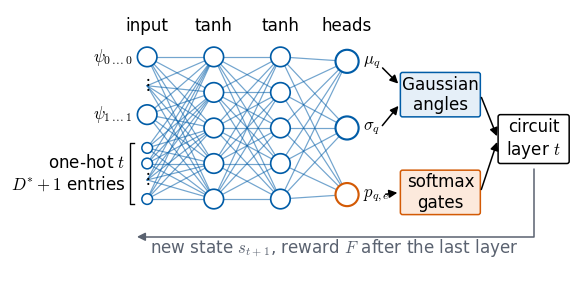

In [26]:
def draw_policy_network(ax):
    """Nodes-and-edges drawing of the policy network with its three heads and the loop with the circuit."""
    # input: amplitudes psi at the top, the one-hot entries of the step index t (small nodes) below
    amp_labels = [r"$\psi_{0\dots0}$", r"$\vdots$", r"$\psi_{1\dots1}$"]
    layers = [("input", amp_labels + ["onehot", "onehot", r"$\vdots$", "onehot"], 0.0),
              ("tanh", [""] * 5, 1.5), ("tanh", [""] * 5, 3.0)]
    heads = [(r"$\mu_q$", 1.5, UJBlue), (r"$\sigma_q$", 0.0, UJBlue), (r"$p_{q,e}$", -1.5, DSOrange)]
    pos = [[(0.0, y) for y in [1.6, 0.95, 0.3, -0.45, -0.8, -1.17, -1.6]]]
    for title, nodes, x in layers[1:]:
        pos.append([(x, y) for y in np.linspace(1.6, -1.6, len(nodes))])
    for title, nodes, x in layers:
        ax.text(x, 2.3, title, ha="center", va="center")
    head_pos = [(4.5, y) for _, y, _ in heads]
    for P, Q in list(zip(pos[:-1], pos[1:])) + [(pos[-1], head_pos)]:
        for p in P:
            for q in Q:
                ax.plot([p[0], q[0]], [p[1], q[1]], color=UJBlue, alpha=0.55, lw=0.8, zorder=0)
    for (title, nodes, x), P in zip(layers, pos):
        for lab, p in zip(nodes, P):
            if lab == r"$\vdots$":
                ax.text(p[0], p[1] + 0.05, lab, ha="center", va="center", fontsize=11); continue
            if lab == "onehot":
                ax.add_patch(Circle(p, 0.12, fc="white", ec=UJBlue, lw=1.0, zorder=2)); continue
            ax.add_patch(Circle(p, 0.22, fc="white", ec=UJBlue, lw=1.1, zorder=2))
            if lab:
                ax.text(p[0] - 0.32, p[1], lab, ha="right", va="center")
    for (lab, y, c), p in zip(heads, head_pos):
        ax.add_patch(Circle(p, 0.26, fc="white", ec=c, lw=1.4, zorder=2))
        ax.text(p[0] + 0.36, y, lab, ha="left", va="center")
    ax.plot([-0.3, -0.38, -0.38, -0.3], [-0.33, -0.33, -1.72, -1.72], color="k", lw=0.9)     # bracket of the one-hot block
    ax.text(-0.48, -1.02, "one-hot $t$\n$D^{*}+1$ entries", ha="right", va="center")
    ax.text(4.5, 2.3, "heads", ha="center", va="center")
    ax.add_patch(FancyBboxPatch((5.75, 0.3), 1.7, 0.9, boxstyle="round,pad=0.05", fc="#E5EFF8", ec=UJBlue))
    ax.text(6.6, 0.75, "Gaussian\nangles", ha="center", va="center")
    ax.add_patch(FancyBboxPatch((5.75, -1.9), 1.7, 0.9, boxstyle="round,pad=0.05", fc="#FCE9DC", ec=DSOrange))
    ax.text(6.6, -1.45, "softmax\ngates", ha="center", va="center")
    ax.add_patch(FancyBboxPatch((7.95, -0.75), 1.5, 1.0, boxstyle="round,pad=0.05", fc="white", ec="k"))
    ax.text(8.7, -0.25, "circuit\nlayer $t$", ha="center", va="center")
    for (x0, y0), (x1, y1) in (((5.25, 1.4), (5.7, 0.95)), ((5.25, 0.0), (5.7, 0.55)), ((5.3, -1.5), (5.7, -1.45))):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="k"))
    for y0 in (0.75, -1.45):
        ax.annotate("", xy=(7.9, -0.25), xytext=(7.5, y0), arrowprops=dict(arrowstyle="-|>", color="k"))
    ax.annotate("", xy=(-0.3, -2.45), xytext=(8.7, -0.85),
                arrowprops=dict(arrowstyle="-|>", color=UJGray, connectionstyle="angle,angleA=-90,angleB=180,rad=0"))
    ax.text(4.2, -2.8, r"new state $s_{t+1}$, reward $F$ after the last layer", ha="center", color=UJGray)
    ax.set_xlim(-2.0, 9.6); ax.set_ylim(-3.22, 2.64); ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(5.5, 3.0))
draw_policy_network(ax)
fig.tight_layout(); save(fig, "fig_lab055_policy_network"); plt.show()

The input layer receives the state features, the amplitudes $\psi_{s_0\dots s_{N-1}}$ and the step index $t$, which enters as a one-hot vector of $D+1$ entries with $D=D^\ast$, drawn as the column of small nodes. Two hidden layers of 64 tanh units feed three heads, the means $\mu_q$ and widths $\sigma_q$ of the Gaussian angles and the softmax probabilities $p_{q,e}$ of the gate types. The sampled angles and gate types make one layer of the circuit, and the new state is the next input. The arrow back to the input closes the loop of one episode.
<hr/>
## 7. Training the agent

An episode with the policy alternates between the agent and the environment. At every step the network computes $(\boldsymbol\mu,\boldsymbol\sigma,p)$ from the state features, the angles are sampled as $a_{t,q}=\mu_q+\sigma_q u_{t,q}$ with standard normal numbers $u_{t,q}$, the gate types are sampled from the softmax, and the environment applies them. The function `rollout` below plays one episode as a `lax.scan` over the $D+1$ steps and returns the return $G$, the summed log-likelihood $\sum_t\ln\pi_\phi(\mathbf a_t,\mathbf e_t|s_t)$, the angles, the gate types and the widths along the episode. With `greedy=True` it plays the means and the most probable gate types instead of samples, which is the circuit the agent proposes as its answer. The softmax log-likelihood of the last step is left out, since the last layer has no two-qubit gates.

In [27]:
def rollout(net, key, target, N, D, greedy=False):
    """One episode: G (= final F), sum_t ln pi, angles (D+1, N), gate types (D+1, N-1), widths (D+1, N)."""
    def step(carry, inp):
        s, logp = carry
        t, key_t = inp
        mu, nu, logits = policy(net, observe(s, D))
        k_a, k_e = jax.random.split(key_t)
        a_t = mu if greedy else mu + jnp.exp(nu) * jax.random.normal(k_a, mu.shape)   # a = mu + sigma u
        e_t = jnp.argmax(logits, -1) if greedy else jax.random.categorical(k_e, logits)
        a_t, e_t = jax.lax.stop_gradient(a_t), jax.lax.stop_gradient(e_t)   # samples; gradients flow through ln pi
        logp_e = jnp.sum(jnp.take_along_axis(jax.nn.log_softmax(logits), e_t[:, None], axis=1))
        logp = logp + gaussian_log_prob(a_t, mu, nu) + jnp.where(t < D, logp_e, 0.0)
        s, r_next = env_step(s, a_t, e_t, target, D)
        return (s, logp), (a_t, e_t, jnp.exp(nu), r_next)
    (_, logp), (angles, types, sigmas, rewards) = jax.lax.scan(
        step, (env_reset(N), 0.0), (jnp.arange(D + 1), jax.random.split(key, D + 1)))
    return rewards.sum(), logp, angles, types, sigmas

G_chk, _, angles_chk, types_chk, _ = rollout(net0, key, TARGETS[("W", 4)]["psi"], 4, 2, greedy=True)
print("greedy gate types of the untrained policy:", [[GATE_TYPES[int(e)] for e in row] for row in np.asarray(types_chk)[:2]])
print(f"greedy G = {float(G_chk):.8f},  template F of the same angles = "
      f"{float(template_fidelity(angles_chk, TARGETS[('W', 4)]['psi'])):.8f}")

greedy gate types of the untrained policy: [['CNOT', 'CNOT', 'CNOT'], ['CNOT', 'CNOT', 'CNOT']]
greedy G = 0.00013524,  template F of the same angles = 0.00013524


The untrained policy proposes CNOT on every bond, so its greedy episode is the template with the proposed angles, and the two fidelities agree. The training follows the one-qubit case. `reinforce_loss` plays a batch of $B$ episodes and returns the surrogate loss $-\frac1B\sum_iA_i\ln\pi_\phi(\tau_i)$, with the advantages $A_i=(G_i-\bar G)/\mathrm{std}(G)$ held fixed and $\ln\pi_\phi(\tau_i)$ the summed log-likelihood of episode $i$. Its gradient with respect to $\phi$ is minus the REINFORCE estimate, so `jax.grad` of this loss gives, for all weights of the network, the gradients that were written out for one qubit. The option `shots` replaces the exact fidelity by an estimate from a finite number of measurements, used in the comparison section. `train_reinforce` runs `ITERS` updates with Adam, with the norm of each gradient clipped to one to avoid single large steps, as one compiled `lax.scan`. After every update it records the batch mean of $F$, the fidelity and the widths of the greedy circuit, and the number of two-qubit gates in it. `train_seeds` trains one agent per seed in parallel with `vmap`. This is our implementation of REINFORCE with a batch-mean baseline [Williams (1992)] on exact state vectors.

In [28]:
ITERS, BATCH, LR, SEEDS = 1500, 32, 3e-3, (0, 1, 2)

def reinforce_loss(net, key, target, N, D, batch, shots):
    """Surrogate loss whose gradient is minus the REINFORCE estimate with the normalised batch-mean baseline.
    shots > 0 replaces the exact fidelity by a binomial estimate from `shots` measurements."""
    G, logp, _, _, _ = jax.vmap(lambda k: rollout(net, k, target, N, D))(jax.random.split(key, batch))
    R = G
    if shots:
        R = jax.random.binomial(jax.random.fold_in(key, 1), shots, jnp.clip(G, 0.0, 1.0)) / shots
    A = (R - R.mean()) / (R.std() + 1e-8)
    return -jnp.mean(jax.lax.stop_gradient(A) * logp), G

@partial(jax.jit, static_argnames=("N", "D", "iters", "batch", "shots"))
def train_reinforce(seed, target, N, D, iters=ITERS, batch=BATCH, lr=LR, shots=0):
    """A full REINFORCE training run as one lax.scan; returns the final network and per-update records."""
    key, k_init = jax.random.split(jax.random.PRNGKey(seed))
    net = init_policy(k_init, N, D)
    opt = optax.chain(optax.clip_by_global_norm(1.0), optax.adam(lr))
    grad_fn = jax.value_and_grad(reinforce_loss, has_aux=True)
    def update(carry, key):
        net, opt_state = carry
        k_batch, k_greedy = jax.random.split(key)
        (_, G), grads = grad_fn(net, k_batch, target, N, D, batch, shots)
        upd, opt_state = opt.update(grads, opt_state)
        net = optax.apply_updates(net, upd)
        F_greedy, _, _, types, sigmas = rollout(net, k_greedy, target, N, D, greedy=True)
        return (net, opt_state), dict(F_batch=G.mean(), F_greedy=F_greedy, sigma=sigmas,
                                      n_2q=jnp.sum(types[:D] != NONE))
    (net, _), rec = jax.lax.scan(update, (net, opt.init(net)), jax.random.split(key, iters))
    return net, rec

@partial(jax.jit, static_argnames=("N", "D", "shots"))
def train_seeds(target, N, D, shots=0):
    """One agent per seed in SEEDS, trained in parallel (vmap); outputs carry a leading seed axis."""
    return jax.vmap(lambda s: train_reinforce(s, target, N, D, shots=shots))(jnp.array(SEEDS))

A first run on the Bell state, $N=2$ and $D=1$, shows what the records contain.

In [29]:
net_bell, rec_bell = train_reinforce(0, bell_state("phi+"), 2, 1)
for i in (0, 10, 50, 200, ITERS - 1):
    print(f"update {i:4d}: greedy F = {float(rec_bell['F_greedy'][i]):.5f}, batch mean F = {float(rec_bell['F_batch'][i]):.5f}, "
          f"widths = {np.round(np.asarray(rec_bell['sigma'][i]).reshape(-1), 3)}")
G_b, _, angles_b, types_b, _ = rollout(net_bell, key, bell_state("phi+"), 2, 1, greedy=True)
print("learned angles (rows t = 0, 1):", np.round(np.asarray(angles_b), 3).tolist(), " gate on the bond:", GATE_TYPES[int(types_b[0, 0])])

update    0: greedy F = 0.53921, batch mean F = 0.39908, widths = [0.483 0.462 0.482 0.461]
update   10: greedy F = 0.98051, batch mean F = 0.81083, widths = [0.314 0.251 0.326 0.324]
update   50: greedy F = 0.99984, batch mean F = 0.99900, widths = [0.018 0.023 0.027 0.027]
update  200: greedy F = 0.99952, batch mean F = 0.99966, widths = [0.007 0.007 0.008 0.008]
update 1499: greedy F = 0.99965, batch mean F = 0.99971, widths = [0.007 0.007 0.007 0.007]


learned angles (rows t = 0, 1): [[1.606, -0.011], [0.285, 0.278]]  gate on the bond: CNOT


The greedy fidelity exceeds 0.99 within a few dozen updates. The batch mean lags behind, since the sampled angles scatter around the means with the widths $\sigma$, and it approaches the greedy value as the widths shrink to the lower bound of 0.007 rad. The learned circuit has a CNOT on the bond and the angle $1.61\approx\pi/2$ on qubit 0 in the first layer. The last layer rotates both qubits by the same angle of about 0.28 rad, which leaves the Bell state unchanged, since $\hat R_Y(a)\otimes \hat R_Y(a)\,|\Phi^+\rangle=|\Phi^+\rangle$ for every angle $a$. The agent found one of the many circuits with $F\approx1$.

The next cell trains three agents, one per seed, for every target on $N=2$, 4 and 6 qubits, each with the depth $D^\ast$ found by gradient ascent. The eight-qubit chains stay with the gradient-ascent reference, because training agents on them does not fit the runtime of this notebook.

In [30]:
NS_RL = (2, 4, 6)
t0 = time.time()
RL = {}
for N in NS_RL:
    for fam in FAMILIES:
        D = GA[(fam, N)]["D_star"]
        target = TARGETS[(fam, N)]["psi"]
        nets, rec = train_seeds(target, N, D)
        F_final, _, angles, types, _ = jax.vmap(lambda n: rollout(n, key, target, N, D, greedy=True))(nets)
        rec = jax.tree_util.tree_map(np.asarray, rec)
        RL[(fam, N)] = dict(D=D, F=np.asarray(F_final), angles=np.asarray(angles), types=np.asarray(types),
                            F_greedy=rec["F_greedy"], F_batch=rec["F_batch"], sigma=rec["sigma"], n_2q=rec["n_2q"])
    print(f"N={N}: " + ", ".join(f"{fam} F={np.median(RL[(fam, N)]['F']):.4f}" for fam in FAMILIES),
          f"[{time.time() - t0:.0f} s]")
T_RL = time.time() - t0

N=2: GHZ F=0.9998, W F=0.9992, TFI h=0.5 F=0.9999, TFI h=1 F=0.9994, TFI h=2 F=0.9998, non-integrable F=0.9998 [16 s]


N=4: GHZ F=0.9998, W F=0.9985, TFI h=0.5 F=0.9990, TFI h=1 F=0.9939, TFI h=2 F=0.9988, non-integrable F=0.9607 [48 s]


N=6: GHZ F=0.9997, W F=0.9746, TFI h=0.5 F=0.9909, TFI h=1 F=0.9930, TFI h=2 F=0.9975, non-integrable F=0.9920 [122 s]


Every agent is trained with $B=32$ episodes per update for 1500 updates, which is 48 000 sampled episodes, plus one episode with the policy means and the most probable gate types after each update to record the proposed circuit. The printed fidelity is the median over the three seeds of that circuit after the last update. On two qubits every median lies above 0.999. On four qubits the medians lie between 0.994 and 0.9998 except for the non-integrable ground state, and on six qubits GHZ, the TFI ground states and the non-integrable ground state reach 0.991 to 0.9997, while the W state reaches 0.975. The next two sections look at these numbers in detail.
<hr/>
## 8. Learning curves and learned circuits

The first figure follows the training of all targets on four and six qubits. The horizontal axis counts fidelity evaluations, $B+1=33$ per update, since on a device every evaluation is one experiment.

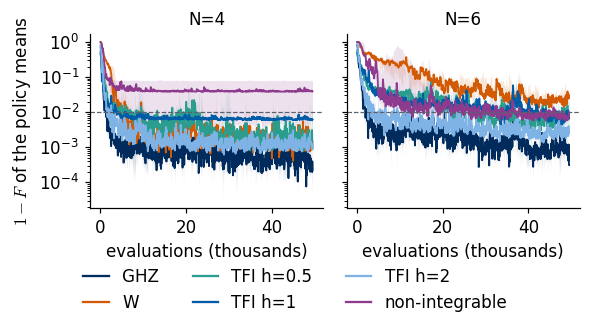

In [31]:
def episodes_axis(n):
    """Fidelity evaluations after each update, in thousands: B sampled episodes plus one greedy episode per update."""
    return (np.arange(n) + 1) * (BATCH + 1) / 1000

fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.6), sharey=True)
for ax, N in zip(axes, (4, 6)):
    for fam in FAMILIES:
        r = RL[(fam, N)]
        inf = np.clip(1 - r["F_greedy"], 1e-5, None)
        x = episodes_axis(inf.shape[1])
        st = FAMILY_STYLE[fam]
        ax.semilogy(x, np.median(inf, 0), color=st["color"], lw=1.2)
        ax.fill_between(x, inf.min(0), inf.max(0), color=st["color"], alpha=0.15, lw=0)
    ax.axhline(1 - F_GOAL, color=UJGray, lw=0.8, ls="--")
    ax.set_title(f"N={N}"); ax.set_xlabel("evaluations (thousands)")
axes[0].set_ylabel(r"$1-F$ of the policy means")
handles = [Line2D([], [], color=FAMILY_STYLE[f]["color"], lw=1.5) for f in FAMILIES]
fig.legend(handles, FAMILIES, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.17), handlelength=1.5)
fig.tight_layout(); save(fig, "fig_lab055_learning"); plt.show()

The curves show the infidelity $1-F$ of the circuit proposed by the policy, the median over three seeds with the band between the best and the worst seed, and the dashed line marks $F=0.99$. On four qubits five of the six targets cross the line within a few thousand evaluations, GHZ first. The median of the non-integrable ground state levels off at about $F=0.96$, since two of its three agents settle on a circuit with fewer or different two-qubit gates (table below). On six qubits GHZ and the paramagnetic TFI ground state cross the line early, the ferromagnetic and critical TFI ground states and the non-integrable ground state cross it after about $10^4$ to $3\times10^4$ evaluations (table in the comparison section), and the W state, whose template has 30 angles, ends at a median $F=0.975$. The six-qubit curves are still falling at the end of the run. The budget of 1500 updates is set by the runtime of the notebook.

The next figure looks inside one agent, for the critical TFI ground state on four qubits, where the template has one entangling layer and eight angles. It shows how the widths $\sigma_{t,q}$ of the Gaussians, which the network computes from the state, evolve along the greedy episode.

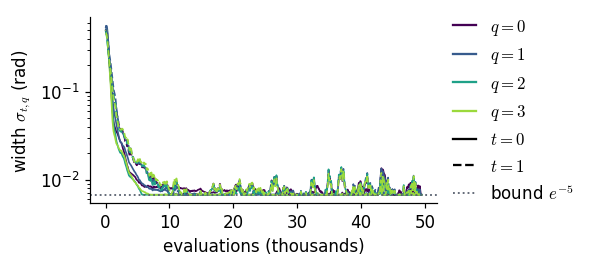

all widths within 1.5 e^-5 after 7722 evaluations, largest width after that 0.0139 rad
TFI h=1, N=4, seed 0: widths fall from 0.5 rad to 0.007..0.007 rad


In [32]:
fam_s, N_s = "TFI h=1", 4
r = RL[(fam_s, N_s)]
sig = r["sigma"][0]                                  # seed 0, widths of the greedy episode, shape (updates, D+1, N)
x = episodes_axis(sig.shape[0])
fig, ax = plt.subplots(figsize=(5.5, 2.5))
cols = plt.cm.viridis(np.linspace(0, 0.85, sig.shape[2]))
for t in range(sig.shape[1]):
    for q in range(sig.shape[2]):
        ax.semilogy(x, sig[:, t, q], color=cols[q], ls=("-", "--", ":")[t], lw=1.1)
ax.axhline(np.exp(-5.0), color=UJGray, lw=1.2, ls=":")
ax.set_xlabel("evaluations (thousands)"); ax.set_ylabel(r"width $\sigma_{t,q}$ (rad)")
ax.legend([Line2D([], [], color=cols[q]) for q in range(sig.shape[2])] +
          [Line2D([], [], color="k", ls=("-", "--", ":")[t]) for t in range(sig.shape[1])] +
          [Line2D([], [], color=UJGray, lw=1.2, ls=":")],
          [f"$q={q}$" for q in range(sig.shape[2])] + [f"$t={t}$" for t in range(sig.shape[1])] + [r"bound $e^{-5}$"],
          ncol=1, loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.4)
fig.tight_layout(); save(fig, "fig_lab055_sigma"); plt.show()
k = int(np.argmax(sig.reshape(sig.shape[0], -1).max(1) < 1.5 * np.exp(-5.0)))
NUMBERS["sigma_floor_evals"] = float(x[k] * 1000)
print(f"all widths within 1.5 e^-5 after {x[k] * 1000:.0f} evaluations, largest width after that {sig[k:].max():.4f} rad")
NUMBERS["sigma_final_min"] = float(sig[-1].min()); NUMBERS["sigma_final_max"] = float(sig[-1].max())
print(f"{fam_s}, N={N_s}, seed 0: widths fall from 0.5 rad to {sig[-1].min():.3f}..{sig[-1].max():.3f} rad")

All widths start near 0.5 rad and contract to the lower bound $e^{-5}\approx0.007$ rad set in the network, all of them within $1.5\,e^{-5}$ after about 7700 evaluations (printed above), as in the one-qubit case. Later they fluctuate between the bound and 0.014 rad, about twice the bound. The policy has become sure of every angle. The lower bound keeps a minimum of exploration and prevents the log-likelihood from diverging.

The circuits proposed by the agents can be drawn with their angles and gates. The next cell draws the best of the three agents for the W state and for the non-integrable Ising ground state on four qubits.

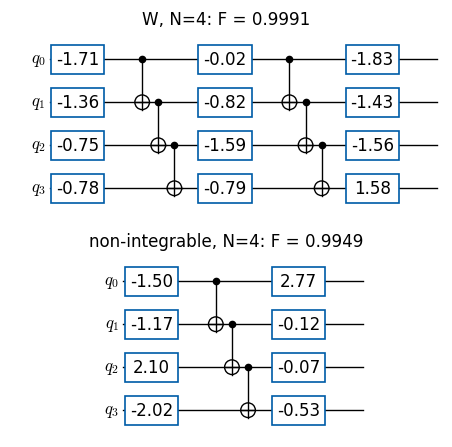

In [33]:
def wrap(a):
    return (np.asarray(a) + np.pi) % (2 * np.pi) - np.pi

fig, axes = plt.subplots(2, 1, figsize=(5.5, 4.2))
for ax, (fam, N) in zip(axes, (("W", 4), ("non-integrable", 4))):
    r = RL[(fam, N)]
    best = int(np.argmax(r["F"]))
    draw_circuit(ax, N, r["D"], r["angles"][best], r["types"][best], title=f"{fam}, N={N}: F = {r['F'][best]:.4f}")
fig.tight_layout(); save(fig, "fig_lab055_circuits"); plt.show()

The boxes show the learned angles in radians, wrapped into $(-\pi,\pi]$, which are the means of the final policy, and the two-qubit gates the agent chose. In both circuits the agent kept a CNOT on every bond. The W circuit uses angles that are not multiples of $\pi/4$, for example $-1.36$ and $-0.82$ rad.

The next cell collects all targets in one table, with the template depth $D^\ast$, the numbers of CNOT and $\hat R_Y$ gates of the template, the half-chain entropy, the gradient-ascent fidelity at the same depth, the final fidelities of the three agents, and the number of two-qubit gates each agent placed, with the number of CZ gates in brackets. The last column anticipates the comparison with discrete gates and is explained there.

In [34]:
rows = []
print(f"{'target':>15} {'N':>2} {'D*':>3} {'CNOT':>4} {'R_Y':>4} {'S_N/2':>6} {'F_GA':>7} {'F_RL (3 seeds)':>24} "
      f"{'2q gates (CZ)':>16} {'F_RL pi/4 grid':>15}")
for N in NS_RL:
    for fam in FAMILIES:
        r, g = RL[(fam, N)], GA[(fam, N)]
        D = r["D"]
        # angles rounded to the nearest multiple of pi/4, the angles a discrete gate set of this kind could offer
        F_round = [float(circuit_fidelity(jnp.round(jnp.asarray(a) / (np.pi / 4)) * (np.pi / 4), jnp.asarray(e),
                                          TARGETS[(fam, N)]["psi"])) for a, e in zip(r["angles"], r["types"])]
        r["n_2q_final"] = [int((e[:D] != NONE).sum()) for e in r["types"]]
        r["n_cz_final"] = [int((e[:D] == CZ_).sum()) for e in r["types"]]
        r["F_round"] = np.array(F_round)
        r["n_rot_nontrivial"] = [int((np.abs(wrap(a)) > 0.05).sum()) for a in r["angles"]]
        rows.append(dict(family=fam, N=N, D=D, cnot=D * (N - 1), rot=N * (D + 1), S=TARGETS[(fam, N)]["S"],
                         F_GA=g["F_by_D"][D], F_RL=r["F"].tolist(), F_round=F_round,
                         n_rot_nontrivial=r["n_rot_nontrivial"], n_2q=r["n_2q_final"], n_cz=r["n_cz_final"]))
        q2 = " ".join(f"{n}({m})" for n, m in zip(r["n_2q_final"], r["n_cz_final"]))
        print(f"{fam:>15} {N:2d} {D:3d} {D*(N-1):4d} {N*(D+1):4d} {TARGETS[(fam, N)]['S']:6.3f} {g['F_by_D'][D]:7.4f} "
              f"{' '.join(f'{f:.4f}' for f in r['F']):>24} {q2:>16} {np.median(F_round):15.4f}")

         target  N  D* CNOT  R_Y  S_N/2    F_GA           F_RL (3 seeds)    2q gates (CZ)  F_RL pi/4 grid


            GHZ  2   1    1    4  1.000  1.0000     0.9998 0.9998 0.9998   1(0) 1(0) 1(0)          1.0000
              W  2   1    1    4  1.000  1.0000     0.9992 0.9734 0.9999   1(0) 1(0) 1(0)          1.0000
      TFI h=0.5  2   1    1    4  0.601  1.0000     1.0000 0.9997 0.9999   1(0) 1(0) 1(0)          0.9161
        TFI h=1  2   1    1    4  0.298  1.0000     0.9991 1.0000 0.9994   1(0) 1(0) 1(0)          0.9780
        TFI h=2  2   1    1    4  0.112  1.0000     0.9999 0.9995 0.9998   1(0) 1(0) 1(0)          0.9851
 non-integrable  2   1    1    4  0.220  1.0000     0.9999 0.9997 0.9998   1(0) 1(1) 1(0)          0.9430


            GHZ  4   1    3    8  1.000  1.0000     0.9998 0.9999 0.9992   3(0) 3(0) 3(0)          1.0000


              W  4   2    6   12  1.000  1.0000     0.9985 0.9991 0.9952   6(0) 6(0) 6(0)          0.9161
      TFI h=0.5  4   2    6   12  0.865  0.9996     0.9990 0.9994 0.9920   6(0) 6(0) 6(0)          0.9456
        TFI h=1  4   1    3    8  0.411  0.9942     0.9938 0.9939 0.9941   3(0) 3(0) 3(0)          0.9512


        TFI h=2  4   1    3    8  0.126  0.9993     0.9991 0.9986 0.9988   3(0) 3(0) 3(0)          0.9527
 non-integrable  4   1    3    8  0.399  0.9964     0.9199 0.9607 0.9949   2(0) 3(2) 3(0)          0.8464


            GHZ  6   1    5   12  1.000  1.0000     0.9997 0.9989 0.9998   5(0) 5(0) 5(0)          1.0000


              W  6   4   20   30  1.000  0.9935     0.9617 0.9746 0.9855 20(0) 20(0) 20(0)          0.7540


      TFI h=0.5  6   2   10   18  0.964  0.9990     0.9574 0.9909 0.9977 10(0) 10(0) 10(0)          0.8514
        TFI h=1  6   2   10   18  0.473  0.9948     0.9932 0.9930 0.9877 10(0) 10(0) 10(0)          0.8765


        TFI h=2  6   1    5   12  0.128  0.9987     0.9975 0.9981 0.9971   5(0) 5(0) 5(0)          0.9211
 non-integrable  6   2   10   18  0.394  0.9960     0.9920 0.9946 0.9891 10(0) 10(0) 10(0)          0.8092


The table shows that the agents keep a CNOT on almost every bond, so the circuits they find are close to the template. The exceptions are the non-integrable ground state on two and four qubits, where some agents chose CZ gates or left a bond empty, and these are also the agents with the lower fidelities on four qubits. The final fidelities of all agents are plotted per target and qubit number in the next figure, one marker per seed, with the gradient-ascent fidelity at the same depth as a cross.

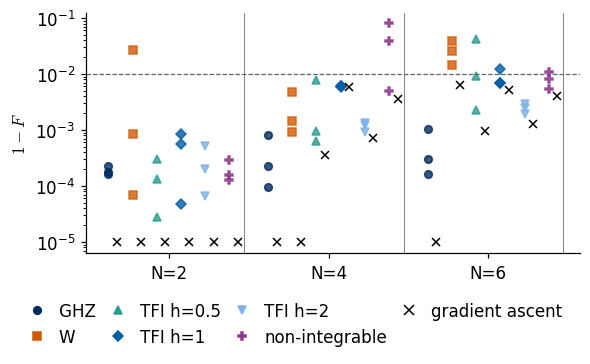

median agent fidelity within 0.01 of gradient ascent for 16 of 18 targets


In [35]:
fig, ax = plt.subplots(figsize=(5.5, 2.8))
xt, xl = [], []
xpos = 0
for N in NS_RL:
    for i, fam in enumerate(FAMILIES):
        r, st = RL[(fam, N)], FAMILY_STYLE[fam]
        ax.plot(np.full(len(SEEDS), xpos), np.clip(1 - r["F"], 1e-5, None), ls="none", ms=5, alpha=0.8,
                color=st["color"], marker=st["marker"])
        ax.plot(xpos + 0.35, max(1 - GA[(fam, N)]["F_by_D"][r["D"]], 1e-5), "x", color="k", ms=5)
        xpos += 1
    xt.append(xpos - len(FAMILIES) / 2 - 0.5); xl.append(f"N={N}")
    ax.axvline(xpos - 0.4, color=UJGray, lw=0.5)
    xpos += 0.6
ax.set_yscale("log"); ax.axhline(1 - F_GOAL, color=UJGray, lw=0.8, ls="--")
ax.set_xticks(xt); ax.set_xticklabels(xl); ax.set_ylabel(r"$1-F$")
handles = [Line2D([], [], ls="none", ms=5, **FAMILY_STYLE[f]) for f in FAMILIES] + [Line2D([], [], ls="none", marker="x", color="k")]
fig.legend(handles, FAMILIES + ["gradient ascent"], loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.2),
           handlelength=1.0, columnspacing=0.8)
fig.tight_layout(); save(fig, "fig_lab055_final_fidelity"); plt.show()
close = sum(GA[(f, N)]["F_by_D"][RL[(f, N)]["D"]] - np.median(RL[(f, N)]["F"]) < 0.01 for N in NS_RL for f in FAMILIES)
print(f"median agent fidelity within 0.01 of gradient ascent for {close} of {len(NS_RL) * len(FAMILIES)} targets")

Infidelities below $10^{-5}$ are drawn at $10^{-5}$. On two qubits all agents but one reach $1-F<10^{-3}$, and on four qubits most agents come within about $10^{-3}$ of the gradient-ascent reference. The critical TFI ground state on four qubits ends at $F=0.994$ for every seed, the fidelity $0.9942$ that gradient ascent reaches with the same template. On six qubits more than half of the agents lie between $1-F=10^{-3}$ and $10^{-2}$, close to the reference, and the W agents end between $F=0.962$ and $0.986$. The median policy-gradient agent reaches $F\ge0.99$ for 16 of the 18 targets. The exceptions are the four-qubit non-integrable ground state, median 0.961, and the six-qubit W state, median 0.975. For 16 of the 18 targets (printed above) the median lies within 0.01 of the gradient-ascent reference.
<hr/>
## 9. Difficulty and entanglement

The cost of a compilation can be measured by the number of fidelity evaluations until the proposed circuit first reaches $F\ge0.99$. The next cell computes this number for every agent and every gradient-ascent start. An agent that does not reach the threshold within the 1500 updates is recorded as not reached.

In [36]:
def evals_to_goal(F_curve, per_step):
    """Fidelity evaluations until the curve first reaches F_GOAL (None if it never does)."""
    idx = np.flatnonzero(np.asarray(F_curve) >= F_GOAL)
    return None if idx.size == 0 else int((idx[0] + 1) * per_step)

for N in NS_RL:
    for fam in FAMILIES:
        r, g = RL[(fam, N)], GA[(fam, N)]
        r["evals"] = [evals_to_goal(c, BATCH + 1) for c in r["F_greedy"]]
        n_ang = N * (r["D"] + 1)
        g["steps"] = [evals_to_goal(c, 1) for c in g["F_steps"]]
        g["n_ang"] = n_ang

The figure relates the cost to the entanglement of the targets.

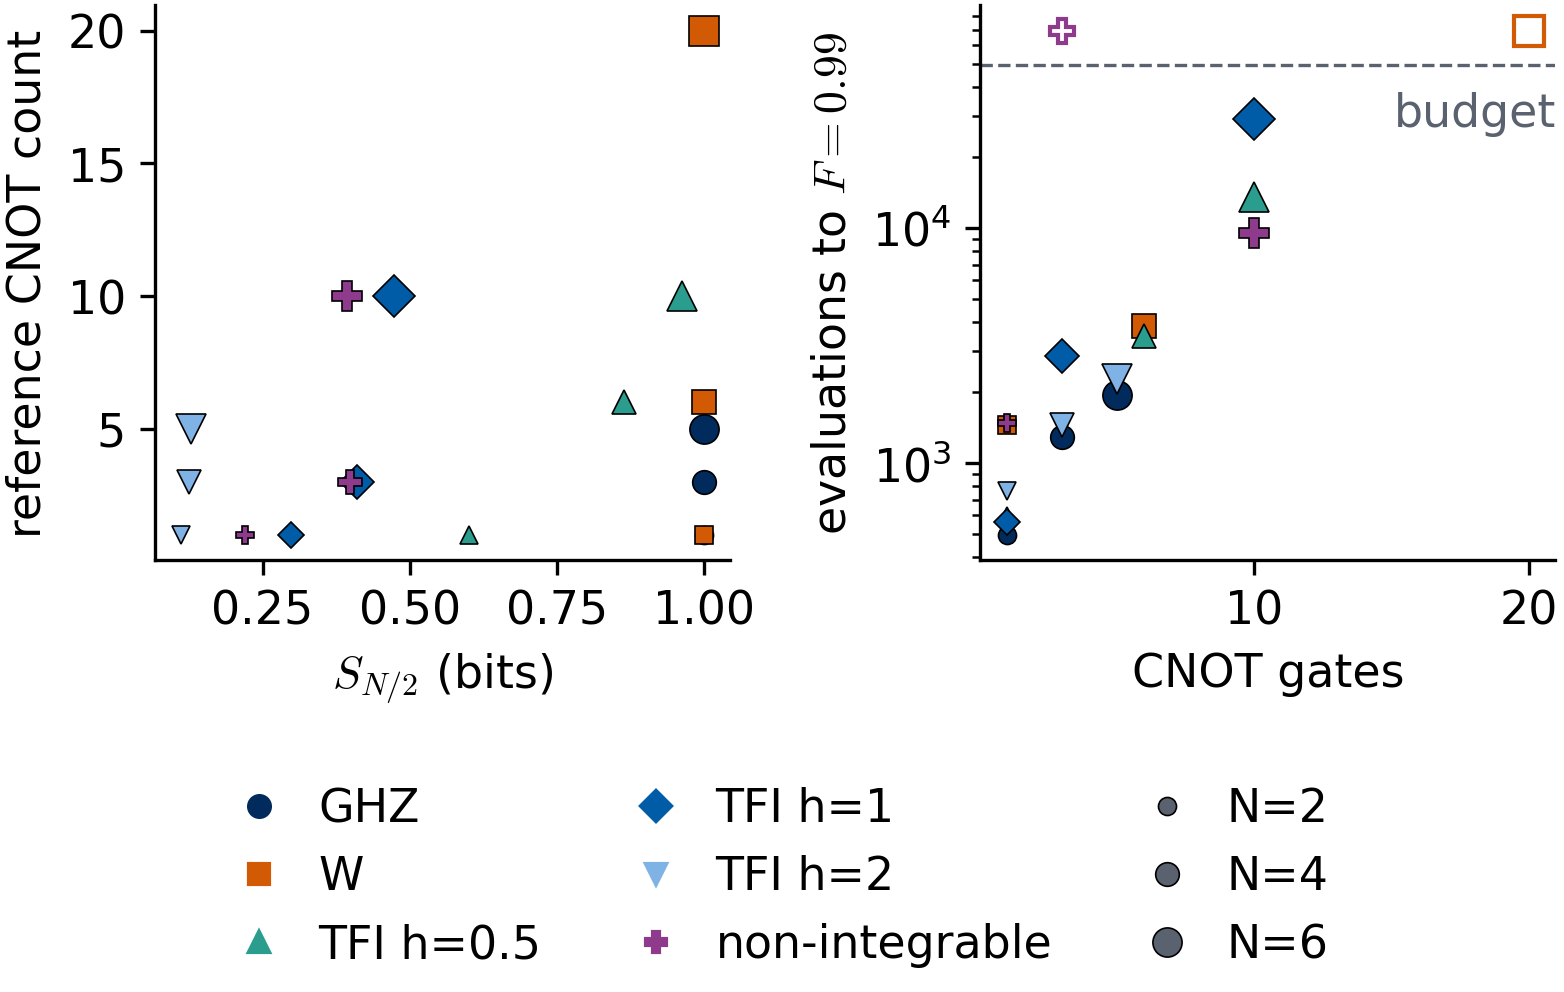

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.7))
for N in NS_RL:
    for fam in FAMILIES:
        st, r = FAMILY_STYLE[fam], RL[(fam, N)]
        axes[0].plot(TARGETS[(fam, N)]["S"], r["D"] * (N - 1), ls="none", ms=3 + N / 1.5, mec="k", mew=0.4, **st)
        ok = [e for e in r["evals"] if e is not None]
        y = np.median(ok) if len(ok) == len(SEEDS) else np.nan
        axes[1].plot(r["D"] * (N - 1), y, ls="none", ms=3 + N / 1.5, mec="k", mew=0.4, **st)
        if len(ok) < len(SEEDS):
            axes[1].plot(r["D"] * (N - 1), 1.4 * ITERS * (BATCH + 1), ls="none", ms=3 + N / 1.5, mfc="none", mec=st["color"], marker=st["marker"])
axes[0].set_xlabel(r"$S_{N/2}$ (bits)"); axes[0].set_ylabel("reference CNOT count")
axes[1].set_xlabel("CNOT gates"); axes[1].set_ylabel("evaluations to $F=0.99$")
axes[1].set_yscale("log"); axes[1].axhline(ITERS * (BATCH + 1), color=UJGray, lw=0.8, ls="--")
axes[1].text(21, ITERS * (BATCH + 1) / 1.3, "budget", ha="right", va="top", color=UJGray)
handles = [Line2D([], [], ls="none", ms=5, **FAMILY_STYLE[f]) for f in FAMILIES]
handles += [Line2D([], [], ls="none", marker="o", color=UJGray, mec="k", mew=0.4, ms=3 + n / 1.5) for n in NS_RL]
fig.legend(handles, FAMILIES + [f"N={n}" for n in NS_RL], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.3), handlelength=1.0)
fig.tight_layout(); save(fig, "fig_lab055_difficulty"); plt.show()

The left panel places every target by its half-chain entropy and the CNOT count of the successful reference template, with the marker size growing with $N$ as in the legend. The right panel shows the median number of fidelity evaluations until $F\ge0.99$, over the three seeds, against the number of CNOT gates. An open marker at the top means that at least one seed did not reach $F=0.99$ within the training budget, marked by the dashed line.

The cost grows with the size of the circuit, from about 500 to 1500 evaluations for one CNOT to about $10^4$ to $3\times10^4$ for ten. Entanglement entropy alone does not predict it. GHZ and W both have $S_{N/2}=1$, yet the explicit GHZ construction uses one entangling layer at every $N$ and is learned within about two thousand evaluations, while the successful tested W templates have two layers on four qubits and four on six and is the most expensive target. The ferromagnetic TFI ground state, with almost one bit, and the critical one, with about half a bit, have the same successful tested depth on six qubits and numbers of evaluations within a factor of about two of each other. In these data the cost follows the depth of the template, which reflects the structure of the state relative to the gate set, more closely than the entropy.
<hr/>
## 10. Comparison with other methods

### Gradient ascent through the simulator

Gradient ascent uses the model of the device. `jax.grad` differentiates the simulated circuit, and each step costs one evaluation of the fidelity and its gradient. On a device the same gradient costs $2n_{\rm ang}$ fidelity measurements by the parameter-shift rule. Policy gradient uses only the returned fidelities and assumes nothing about how the controls enter the device. The next cell lists, for every target, the evaluations the agent needed, the gradient-ascent steps, and the measurements gradient ascent would need on a device, all to the first $F\ge0.99$, as medians over the seeds or starts that reached it.

In [38]:
print(f"{'target':>15} {'N':>2} {'n_ang':>5} {'RL evals':>10} {'GA steps':>9} {'param.-shift evals':>19}")
COMPARE = []
for N in NS_RL:
    for fam in FAMILIES:
        r, g = RL[(fam, N)], GA[(fam, N)]
        ok_rl = [e for e in r["evals"] if e is not None]
        ok_ga = [s for s in g["steps"] if s is not None]
        rl_med = float(np.median(ok_rl)) if len(ok_rl) == len(SEEDS) else None
        ga_med = float(np.median(ok_ga)) if ok_ga else None
        COMPARE.append(dict(family=fam, N=N, n_ang=g["n_ang"], rl=rl_med, ga=ga_med,
                            ps=None if ga_med is None else 2 * g["n_ang"] * ga_med))
        fmt = lambda v: "-" if v is None else f"{v:,.0f}"
        print(f"{fam:>15} {N:2d} {g['n_ang']:5d} {fmt(rl_med):>10} {fmt(ga_med):>9} {fmt(COMPARE[-1]['ps']):>19}")
ratios = [c["rl"] / c["ps"] for c in COMPARE if c["rl"] is not None and c["ps"] is not None]
print(f"policy-gradient evaluations / parameter-shift evaluations: {min(ratios):.1f} to {max(ratios):.1f}"
      f" over the {len(ratios)} targets reached by both")
NUMBERS["ratio_min"], NUMBERS["ratio_max"] = min(ratios), max(ratios)

         target  N n_ang   RL evals  GA steps  param.-shift evals
            GHZ  2     4        495        30                 236
              W  2     4      1,452        48                 384
      TFI h=0.5  2     4        594        18                 144
        TFI h=1  2     4        561        25                 200
        TFI h=2  2     4        759        34                 272
 non-integrable  2     4      1,485        58                 464
            GHZ  4     8      1,287        30                 472
              W  4    12      3,828        96               2,316
      TFI h=0.5  4    12      3,465        52               1,236
        TFI h=1  4     8      2,871        84               1,352
        TFI h=2  4     8      1,452        36                 576
 non-integrable  4     8          -        78               1,240
            GHZ  6    12      1,947        30                 708
              W  6    30          -       172              10,350
      TFI 

The next figure shows the same numbers against the number of angles.

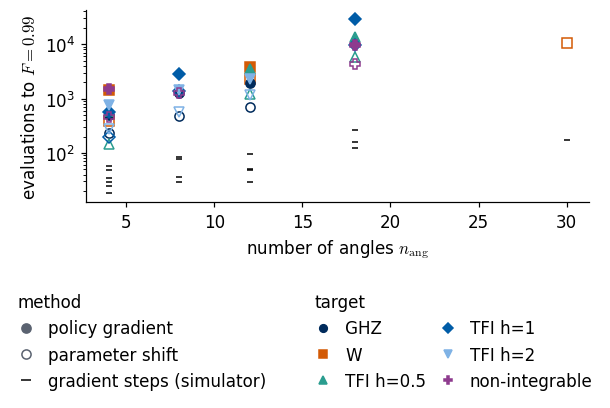

In [39]:
fig, ax = plt.subplots(figsize=(5.5, 2.6))
for c in COMPARE:
    st = FAMILY_STYLE[c["family"]]
    if c["rl"] is not None:
        ax.plot(c["n_ang"], c["rl"], ls="none", ms=6, **st)
    if c["ps"] is not None:
        ax.plot(c["n_ang"], c["ps"], ls="none", ms=6, mfc="none", mec=st["color"], marker=st["marker"])
    if c["ga"] is not None:
        ax.plot(c["n_ang"], c["ga"], ls="none", ms=4, color="k", marker="_")
ax.set_yscale("log")
ax.set_xlabel(r"number of angles $n_{\rm ang}$"); ax.set_ylabel("evaluations to $F=0.99$")
handles = [Line2D([], [], ls="none", marker="o", color=UJGray, ms=6),
           Line2D([], [], ls="none", marker="o", mfc="none", mec=UJGray, ms=6),
           Line2D([], [], ls="none", marker="_", color="k", ms=6)]
handles += [Line2D([], [], ls="none", ms=5, **FAMILY_STYLE[f]) for f in FAMILIES]
fig.legend(handles[:3], ["policy gradient", "parameter shift", "gradient steps (simulator)"], title="method",
           loc="upper left", bbox_to_anchor=(0.0, 0.0), handlelength=1.0, alignment="left")
fig.legend(handles[3:], FAMILIES, title="target", loc="upper right", ncol=2, bbox_to_anchor=(1.0, 0.0),
           handlelength=1.0, columnspacing=0.8, alignment="left")
fig.tight_layout(); save(fig, "fig_lab055_evaluations"); plt.show()

Filled markers are the policy-gradient agents, open markers the measurements gradient ascent with the parameter-shift rule would need, and black bars the gradient steps through the simulator, each one exact gradient computed with `jax.grad`. The left legend gives these three methods, and the right legend the target, which sets the colour and the shape of every marker. Wherever both methods reach $F=0.99$, policy gradient needs between 1.7 and 4.1 times more fidelity evaluations than gradient ascent with parameter-shift gradients (printed above), and one to two orders of magnitude more than the number of gradient steps through the simulator. The parameter-shift count is taken per successful start and excludes the cost of the depth scan. That scan also supplied the template depth $D^\ast$ given to the policy-gradient agents, so the agents received information from the model-based reference.

In these recorded experiments, gradient ascent uses fewer fidelity evaluations for targets reached by both methods. Its reference uses a differentiable simulator or a parameter-shift rule, and the depth scan also covers eight-qubit targets. The policy-gradient score estimator uses sampled rewards without differentiating through the response of the device. The current policy still reads exact simulated amplitudes. Applying it to hardware requires an observation interface and a policy trained for that interface.

### Fidelity estimated from measurements

On a device the fidelity is estimated from $n$ repetitions of the experiment. One way is to run the circuit, then the inverse of a known preparation of the target, and count the runs that end in $|0\dots0\rangle$, which happens with probability $F$. We model the estimate as $\tilde F=k/n$, with $k$ drawn from the binomial distribution with $n=1000$ trials and success probability $F$, and train the agents of two targets again with $\tilde F$ as the reward. The statistical error of one estimate is $\sqrt{F(1-F)/n}$, about $0.003$ at $F=0.99$. The recorded curves still use the exact fidelity of the proposed circuit, which the agent never sees.

TFI h=1, N=6: final F with exact reward [0.9932 0.993  0.9877], with 1000-shot reward [0.9488 0.9686 0.9726]


W, N=4: final F with exact reward [0.9985 0.9991 0.9952], with 1000-shot reward [0.9768 0.9766 0.9745]


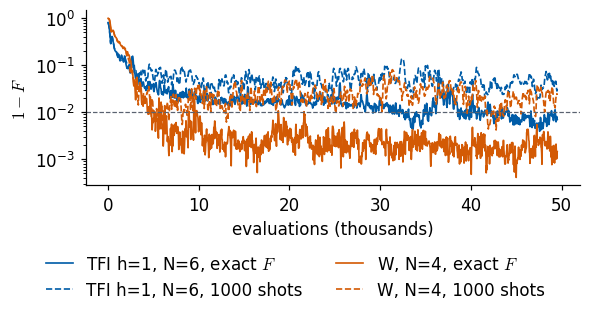

In [40]:
SHOTS = 1000
SHOT_RUNS = {}
fig, ax = plt.subplots(figsize=(5.5, 2.4))
for fam, N in (("TFI h=1", 6), ("W", 4)):
    D, target = RL[(fam, N)]["D"], TARGETS[(fam, N)]["psi"]
    nets, rec = train_seeds(target, N, D, shots=SHOTS)
    F_final = jax.vmap(lambda n: rollout(n, key, target, N, D, greedy=True)[0])(nets)
    SHOT_RUNS[(fam, N)] = np.asarray(F_final)
    st = FAMILY_STYLE[fam]
    for curve, ls, lab in ((RL[(fam, N)]["F_greedy"], "-", "exact $F$"), (np.asarray(rec["F_greedy"]), "--", f"{SHOTS} shots")):
        inf = np.clip(1 - curve, 1e-5, None)
        ax.semilogy(episodes_axis(inf.shape[1]), np.median(inf, 0), color=st["color"], ls=ls, lw=1.1, label=f"{fam}, N={N}, {lab}")
    print(f"{fam}, N={N}: final F with exact reward {np.round(RL[(fam, N)]['F'], 4)}, with {SHOTS}-shot reward {np.round(SHOT_RUNS[(fam, N)], 4)}")
ax.axhline(1 - F_GOAL, color=UJGray, lw=0.8, ls="--")
ax.set_xlabel("evaluations (thousands)"); ax.set_ylabel(r"$1-F$")
fig.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.22), handlelength=1.6)
fig.tight_layout(); save(fig, "fig_lab055_shots"); plt.show()

The solid lines are the agents with the exact reward, the dashed lines the agents with the 1000-shot estimate, both medians over three seeds. Training with measured fidelities works and ends lower, at $F=0.95$ to $0.97$ for the critical TFI ground state on six qubits against $0.988$ to $0.993$ with the exact reward, and at $F\approx0.975$ for the W state on four qubits against $0.995$ to $0.999$. A likely reason is that near $F=1$ the differences between the sampled circuits of a batch become comparable with the measurement error of about $0.003$, so that the advantages are dominated by noise. More shots per evaluation or larger batches are expected to reduce this effect at a higher measurement cost, which we have not tested here. Automatic differentiation with `jax.grad` uses the simulator. On a device, the parameter-shift rule estimates the same derivatives from finite-shot fidelity measurements, with statistical uncertainty and an explicit measurement cost. That finite-shot gradient-ascent comparison was not performed in this recorded experiment.

### Discrete angles

The deep Q-learning notebook solves the same compilation task with a discrete gate set. A first measure of what discrete angles cost comes from this notebook alone. We round every learned angle to the nearest multiple of $\pi/4$, keep the learned two-qubit gates, and evaluate the fidelity of the rounded circuit.

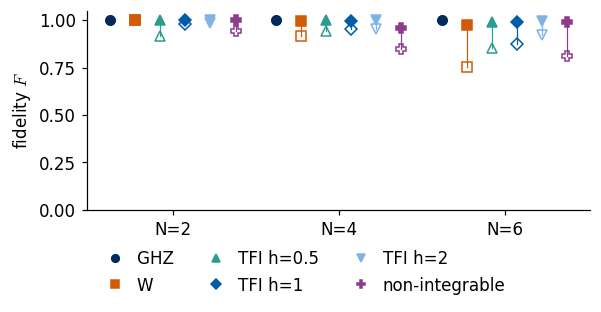

In [41]:
fig, ax = plt.subplots(figsize=(5.5, 2.4))
xpos, xt, xl = 0, [], []
for N in NS_RL:
    for fam in FAMILIES:
        r, st = RL[(fam, N)], FAMILY_STYLE[fam]
        ax.plot(xpos, np.median(r["F"]), ls="none", ms=6, **st)
        ax.plot(xpos, np.median(r["F_round"]), ls="none", ms=6, mfc="none", mec=st["color"], marker=st["marker"])
        ax.plot([xpos, xpos], [np.median(r["F_round"]), np.median(r["F"])], color=st["color"], lw=0.8)
        xpos += 1
    xt.append(xpos - len(FAMILIES) / 2 - 0.5); xl.append(f"N={N}"); xpos += 0.6
ax.set_xticks(xt); ax.set_xticklabels(xl); ax.set_ylabel("fidelity $F$"); ax.set_ylim(0, 1.05)
handles = [Line2D([], [], ls="none", ms=5, **FAMILY_STYLE[f]) for f in FAMILIES]
fig.legend(handles, FAMILIES, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.2), handlelength=1.0)
fig.tight_layout(); save(fig, "fig_lab055_rounding"); plt.show()

Filled markers give the median fidelity of the learned circuits, open markers the same circuits with all angles rounded to multiples of $\pi/4$. GHZ keeps $F=1$, so its learned angles lie close to multiples of $\pi/4$ that prepare GHZ. The W state keeps $F=1$ on two qubits, drops to $0.92$ on four and to $0.75$ on six. The ground states drop to between $0.81$ and $0.99$. Most targets need angles between the grid points, which a continuous policy provides.

### Discrete agents

The deep Q-learning notebook trains a deep Q-network (DQN) and a double deep Q-network (DDQN) [H. van Hasselt, A. Guez, D. Silver, Proc. AAAI Conf. Artif. Intell. **30** (2016), [doi:10.1609/aaai.v30i1.10295](https://doi.org/10.1609/aaai.v30i1.10295)] on the same targets. Their actions are the gates $\hat H$, $\hat S$ and $\hat T$ on every qubit and CNOT gates in both directions between neighbours, at most 8, 12 and 16 gates for $N=2,4,6$, and their reward is also built from the fidelity. If its results file is available, the next cell checks that both notebooks use the same target states and compares the fidelities.

         target  N  overlap  F_DQN F_DDQN   F_PG   F_GA   gates DQN/DDQN/PG template/PG non-trivial
            GHZ  2  1.00000  0.500  1.000  1.000  1.000   2/2/5/4
              W  2  1.00000  0.854  0.854  0.999  1.000   6/6/5/4
      TFI h=0.5  2  1.00000  0.854  0.854  1.000  1.000   2/2/5/5
        TFI h=1  2  1.00000  0.947  0.947  0.999  1.000   2/2/5/5
        TFI h=2  2  1.00000  0.985  0.985  1.000  1.000   2/2/5/5
 non-integrable  2  1.00000  0.905  0.767  1.000  1.000   8/8/5/5
            GHZ  4  1.00000  0.500  1.000  1.000  1.000   1/4/11/4
              W  4  1.00000  0.500  0.562  0.999  1.000   5/7/18/18
      TFI h=0.5  4  1.00000  0.805  0.402  0.999  1.000   4/3/18/16
        TFI h=1  4  1.00000  0.813  0.813  0.994  0.994   4/4/11/7
        TFI h=2  4  1.00000  0.953  0.953  0.999  0.999   4/4/11/9
 non-integrable  4  1.00000  0.220  0.741  0.961  0.996   7/10/11/11
            GHZ  6  1.00000  0.500  0.500  1.000  1.000   1/1/17/6
              W  6  1.00000  0.

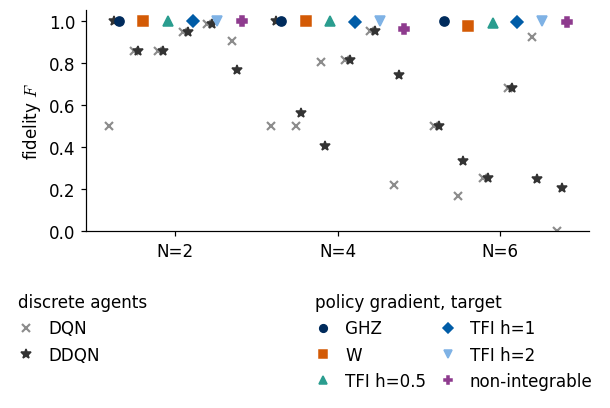

In [42]:
LAB052 = None
for p in ("lab052_results.json", os.path.join(DATA, "lab052_results.json")):
    if os.path.exists(p):
        with open(p) as f:
            LAB052 = json.load(f)
        break
ROWS52 = []
if LAB052 is None:
    print("results of the deep Q-learning notebook not available, the discrete agents are left out of this comparison")
else:
    for N in NS_RL:
        res, tg = LAB052.get("results", {}).get(str(N)), LAB052.get("targets", {}).get(str(N), {})
        if res is None:
            continue
        for fam in FAMILIES:
            r = RL[(fam, N)]
            row = dict(N=N, family=fam, PG=float(np.median(r["F"])), GA=GA[(fam, N)]["F_by_D"][r["D"]],
                       gates_PG=N * (r["D"] + 1) + r["D"] * (N - 1),
                       gates_PG_nontrivial=int(np.median(np.array(r["n_rot_nontrivial"]) + np.array(r["n_2q_final"]))), same_target=np.nan)
            if fam in tg:     # the two notebooks must compile the same state (up to a global phase)
                v = jnp.asarray(np.array(tg[fam]["re"]) + 1j * np.array(tg[fam]["im"]), dtype=CDTYPE).reshape((2,) * N)
                row["same_target"] = float(fidelity_pure(v, TARGETS[(fam, N)]["psi"]))
            for algo in ("DQN", "DDQN"):
                d = res.get(f"{fam}|{algo}")
                if d is not None:
                    row[algo], row[algo + "_gates"] = float(np.median(d["F"])), float(np.median(d["n"]))
            ROWS52.append(row)
    print(f"{'target':>15} {'N':>2} {'overlap':>8} {'F_DQN':>6} {'F_DDQN':>6} {'F_PG':>6} {'F_GA':>6}   gates DQN/DDQN/PG template/PG non-trivial")
    for w in ROWS52:
        print(f"{w['family']:>15} {w['N']:2d} {w['same_target']:8.5f} {w.get('DQN', np.nan):6.3f} {w.get('DDQN', np.nan):6.3f} "
              f"{w['PG']:6.3f} {w['GA']:6.3f}   {w.get('DQN_gates', np.nan):.0f}/{w.get('DDQN_gates', np.nan):.0f}/{w['gates_PG']}/{w['gates_PG_nontrivial']}")
    fig, ax = plt.subplots(figsize=(5.5, 2.6))
    xpos, xt, xl = 0, [], []
    for N in sorted({w["N"] for w in ROWS52}):
        for w in [w for w in ROWS52 if w["N"] == N]:
            st = FAMILY_STYLE[w["family"]]
            ax.plot(xpos - 0.2, w.get("DQN", np.nan), "x", ms=5, mew=1.4, color="0.55")
            ax.plot(xpos, w.get("DDQN", np.nan), "*", ms=7, color="0.2")
            ax.plot(xpos + 0.2, w["PG"], ls="none", ms=6, **st)
            xpos += 1
        xt.append(xpos - len(FAMILIES) / 2 - 0.5); xl.append(f"N={N}"); xpos += 0.6
    ax.set_xticks(xt); ax.set_xticklabels(xl); ax.set_ylabel("fidelity $F$"); ax.set_ylim(0, 1.05)
    handles = [Line2D([], [], ls="none", marker="x", mew=1.4, color="0.55", ms=5), Line2D([], [], ls="none", marker="*", color="0.2", ms=7)]
    handles += [Line2D([], [], ls="none", ms=5, **FAMILY_STYLE[f]) for f in FAMILIES]
    fig.legend(handles[:2], ["DQN", "DDQN"], title="discrete agents", loc="upper left", bbox_to_anchor=(0.0, 0.0),
               handlelength=1.0, alignment="left")
    fig.legend(handles[2:], FAMILIES, title="policy gradient, target", loc="upper right", ncol=2, bbox_to_anchor=(1.0, 0.0),
               handlelength=1.0, columnspacing=0.8, alignment="left")
    fig.tight_layout(); save(fig, "fig_lab055_vs_dqn"); plt.show()

The overlaps in the first column confirm that both notebooks compile the same states. The DQN and DDQN columns are medians of the uniform-cost survey of Lab 052, with the time limit $n_{\max}=2N+4$ and the fidelity-gain reward with gate cost. In the figure the grey crosses are the DQN agents, the dark grey stars the DDQN agents, and the coloured markers the policy-gradient agents, with the colour and shape giving the target. From four qubits on, the policy-gradient agents reach higher fidelities than both discrete agents on every target except GHZ on four qubits, where the DDQN agent also reaches $F\approx1$. The difference is large for the W state and for most ground states, whose amplitudes need angles between the multiples of $\pi/4$ that the gates $\hat H$, $\hat S$ and $\hat T$ produce. The comparison is between two different setups. The discrete agents choose freely among their gates within a budget of at most 16 gates, while the policy-gradient agents fill a template of up to 50 gates with continuous angles. It shows what continuous angles achieve in a circuit that is deep enough. The gate counts in the table, the full template and the number of two-qubit gates plus the rotations with $|\theta|>0.05$ rad, should be read with this in mind.
<hr/>
## 11. Summary

Compiling a state with continuous gate angles is a decision problem with continuous actions. A deep Q-network needs a maximum over all actions at every step, which a continuum does not offer, so we trained the policy itself. A neural network reads the state and the step index and outputs, for every layer of the circuit, Gaussians for the rotation angles and a softmax over none, CNOT and CZ for every bond. It learns from the final fidelity alone through the policy-gradient identity $\nabla\mathcal J=\langle G\,\nabla\ln\pi\rangle$ with a batch-mean baseline. On one qubit this procedure finds the angle $\pi$ of the gate that maps $|0\rangle$ to $|1\rangle$, and the width of the Gaussian shrinks as the policy becomes sure.

On the GHZ state, the W state, the ground states of the transverse-field Ising chain in both phases and at the critical point, and the non-integrable Ising ground state, the median agent reaches $F\ge0.99$ for 16 of the 18 targets on two, four and six qubits, with median fidelities between 0.961 and 0.9999, for most targets within 0.01 of the fidelity that gradient ascent reaches at the same depth. The cost grows with the size of the circuit, and the W state, with the deepest template, is the most expensive. Training agents on eight qubits lies beyond the runtime of this notebook, and the gradient-ascent reference covers that size.

Gradient ascent of the fidelity through the differentiable simulator is the exact-model reference. On the 16 targets reached by both methods it needs between 1.7 and 4.1 times fewer fidelity evaluations than policy gradient even when its gradient is measured with the parameter-shift rule. This count excludes the depth scan, which also fixed the template depth used by the policy-gradient agents. Policy gradient uses sampled fidelities without differentiating through the device response, and it still trains when the fidelity is estimated from 1000 measurements, at a lower final fidelity. These data compare particular agents and references under their stated budgets. They establish no universal ordering of runtime or measurement cost. The current agent also reads exact simulated amplitudes. Control on hardware requires an observation interface and a policy trained for that interface.